<a href="https://colab.research.google.com/github/shreyanshxt/Mlunet-Brain-Tumor-Segmentation/blob/main/BRAIN_TUMOR_MLUNet_XAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor Classification with MLUNet-3D (FFT + Attention Gates) and Quantitative XAI

**Pipeline:** CSV of cases -> preprocess/cache -> stratified K-fold -> train MLUNet (+ baselines) -> classification metrics
-> XAI (Grad-CAM, Integrated Gradients, Occlusion, Attention-gate map, Consensus) -> localization + faithfulness +
agreement + sanity checks -> tables and figures in `OUT_DIR`.

**Run order:** top to bottom. Set the config in cell 2 first.

In [1]:
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Download the dataset to get its local path
dataset_handle = "awsaf49/brats20-dataset-training-validation"
download_path = kagglehub.dataset_download(dataset_handle)
print(f"Dataset downloaded to: {download_path}")

# Scan the downloaded directory for CSV files
csv_files = []
for root, dirs, files in os.walk(download_path):
    for file in files:
        if file.endswith(".csv"):
            # Get path relative to the downloaded directory root
            csv_files.append(os.path.relpath(os.path.join(root, file), download_path))

# select the first available CSV file
if csv_files:
    file_path = csv_files[0]
    print(f"Found relative CSV file to load: {file_path}")
else:
    file_path = ""
    print("No CSV file found inside the dataset directory.")

# Load the dataset with the relative file path
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  dataset_handle,
  file_path,
)

print("First 5 records:", df.head())

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Dataset downloaded to: /kaggle/input/brats20-dataset-training-validation
Found relative CSV file to load: BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData/name_mapping_validation_data.csv
Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
First 5 records:   BraTS_2017_subject_ID BraTS_2018_subject_ID TCGA_TCIA_subject_ID  \
0   Brats17_CBICA_AAM_1   Brats18_CBICA_AAM_1                  NaN   
1   Brats17_CBICA_ABT_1   Brats18_CBICA_ABT_1                  NaN   
2   Brats17_CBICA_ALA_1   Brats18_CBICA_ALA_1                  NaN   
3   Brats17_CBICA_ALT_1   Brats18_CBICA_ALT_1                  NaN   
4   Brats17_CBICA_ALV_1   Brats18_CBICA_ALV_1                  NaN   

  BraTS_2019_subject_ID   BraTS_2020_subject_ID  
0   BraTS19_CBICA_AAM_1  BraTS20_Validation_001  
1   BraTS19_CBICA_ABT_1  BraTS20_Validation_002  
2   BraTS19_CBICA_ALA_1  BraTS20_Val

In [47]:
# ----------------------------- CONFIGURATION CORRECTION ---------------------------------------
# Aligning CFG.XAI_MODEL to match 'MLUNet-CBAM' name registration in order to output XAI metrics.
CFG.XAI_MODEL = "MLUNet-CBAM"
print(f"CFG.XAI_MODEL successfully aligned to: '{CFG.XAI_MODEL}'")

CFG.XAI_MODEL successfully aligned to: 'MLUNet-CBAM'


In [3]:
import os, random, time, warnings, copy
from pathlib import Path
import numpy as np, pandas as pd, nibabel as nib
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, brier_score_loss, roc_curve, confusion_matrix
from scipy.stats import spearmanr, wilcoxon, rankdata
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ----------------------------- CONFIG -----------------------------------------------------------
class CFG:
    # ---- data: one row per patient. columns: case_id, label, <one column per modality path>, seg (optional)
    DATA_CSV   = "/content/labels.csv"
    ID_COL     = "case_id"
    LABEL_COL  = "label"            # 0/1 or strings (e.g. LGG/HGG)
    MOD_COLS   = ["flair", "t1ce"]  # modality path columns = input channels
    SEG_COL    = "seg"              # tumor mask path column, or None. Used for aux segmentation loss + XAI localization
    OUT_DIR    = "/content/out"
    CACHE_DIR  = "/content/cache"
    # ---- compute preset: "fast" (quick first result) or "paper" (final numbers)
    PRESET     = "fast"
    # ---- training
    N_FOLDS    = 5
    RUN_FOLDS  = None               # e.g. [0] to run only fold 0 first
    RUN_MODELS = ["MLUNet", "PlainCNN"]   # add "MLUNet-noFFT" for an ablation
    XAI_MODEL  = "MLUNetCBAM"
    BATCH      = 2
    LR         = 3e-4
    WD         = 1e-4
    PATIENCE   = 8
    SEG_LAMBDA = 0.5
    NUM_WORKERS = 2
    SEED       = 42
    # ---- XAI
    XAI_MAX_CASES = 25              # test cases explained per fold
    IG_STEPS   = 16
    XAI_CHUNK  = 2                  # lower if you hit CUDA OOM
    OCC_WIN_DIV = 6                 # occlusion window = SIZE // OCC_WIN_DIV
    N_SAMPLES_FIG = 4

PRESETS = {
    "fast":  dict(SIZE=96, BASE=8,  EPOCHS=25),
    "paper": dict(SIZE=224, BASE=16, EPOCHS=40),
}
for k, v in PRESETS[CFG.PRESET].items():
    setattr(CFG, k, v)

MODELS = {
    "MLUNet":       dict(use_fft=True,  aux_seg=True),
    "MLUNet-noFFT": dict(use_fft=False, aux_seg=True),
    "PlainCNN":     dict(use_fft=False, aux_seg=False),
}

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG.SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(CFG.OUT_DIR, exist_ok=True); os.makedirs(CFG.CACHE_DIR, exist_ok=True)
print("device:", dev, "| preset:", CFG.PRESET, "| size:", CFG.SIZE, "| base:", CFG.BASE, "| epochs:", CFG.EPOCHS)

device: cuda | preset: fast | size: 96 | base: 8 | epochs: 25


## 1. Build the labels CSV
**Option A (BraTS 2019/2020, HGG vs LGG):** run the helper below. **Option B (anything else):** write your own CSV with
columns `case_id,label,flair,t1ce,seg` (or your own modality columns, e.g. `suv,cbf`; all volumes of a case must share one grid).
BraTS 2021 has no grade labels, so it cannot be used for HGG/LGG classification.

In [4]:
def build_brats_csv(root, out_csv, mods=("flair", "t1ce")):
    root = Path(root); grade_map = {}
    for nm in root.rglob("name_mapping.csv"):
        d = pd.read_csv(nm)
        for col in [c for c in d.columns if "subject_ID" in c]:
            grade_map.update(dict(zip(d[col], d["Grade"])))
    rows = []
    for seg in sorted(root.rglob("*_seg.nii*")):
        cdir = seg.parent; cid = cdir.name
        grade = cdir.parent.name if cdir.parent.name in ("HGG", "LGG") else grade_map.get(cid)
        if grade not in ("HGG", "LGG"): continue
        row = {"case_id": cid, "label": 1 if grade == "HGG" else 0, "seg": str(seg)}
        ok = True
        for m in mods:
            f = list(cdir.glob(f"*_{m}.nii*"))
            if not f: ok = False; break
            row[m] = str(f[0])
        if ok: rows.append(row)
    df = pd.DataFrame(rows); df.to_csv(out_csv, index=False)
    print(df.label.value_counts().rename({1: "HGG", 0: "LGG"}).to_dict(), "->", out_csv); return df

# Corrected the path to use the Kaggle input directory instead of Google Drive
build_brats_csv("/kaggle/input/brats20-dataset-training-validation", CFG.DATA_CSV)

{'HGG': 292, 'LGG': 76} -> /content/labels.csv


,case_id,label,seg,flair,t1ce
0,BraTS20_Training_001,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
1,BraTS20_Training_002,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
2,BraTS20_Training_003,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
3,BraTS20_Training_004,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
4,BraTS20_Training_005,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
...,...,...,...,...,...
363,BraTS20_Training_365,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
364,BraTS20_Training_366,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
365,BraTS20_Training_367,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...
366,BraTS20_Training_368,1,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...,/kaggle/input/brats20-dataset-training-validat...


## 2. (Optional) smoke test on synthetic data
Set `RUN_SMOKE_TEST = True` to verify the whole pipeline runs end-to-end in a couple of minutes before using real data.

In [5]:
RUN_SMOKE_TEST = False
def make_synthetic_dataset(root, n=24, shape=(44, 48, 40), seed=0):
    rng = np.random.RandomState(seed); root = Path(root); root.mkdir(parents=True, exist_ok=True); rows = []
    gx, gy, gz = np.meshgrid(*[np.arange(s) for s in shape], indexing="ij")
    for i in range(n):
        lab = i % 2
        brain = (((gx - shape[0] / 2) / (shape[0] * .45)) ** 2 + ((gy - shape[1] / 2) / (shape[1] * .45)) ** 2 + ((gz - shape[2] / 2) / (shape[2] * .45)) ** 2) < 1
        c = [rng.randint(14, shape[0] - 14), rng.randint(14, shape[1] - 14), rng.randint(14, shape[2] - 14)]
        r = np.sqrt((gx - c[0]) ** 2 + (gy - c[1]) ** 2 + (gz - c[2]) ** 2)
        tumor = (r < 7) & brain
        ring = (r > 4) & (r < 7) & brain
        f = rng.rand(*shape) * .3 + 1.0
        t = rng.rand(*shape) * .3 + 1.0
        f[tumor] += 1.0; t[tumor] += .5 + (1.5 * ring[tumor] * lab)      # class-1 tumors have a bright rim in the 2nd modality
        f *= brain; t *= brain
        d = {"case_id": f"syn{i:03d}", "label": lab}
        for name, arr in (("flair", f), ("t1ce", t), ("seg", tumor.astype(np.uint8))):
            p = root / f"syn{i:03d}_{name}.nii.gz"; nib.save(nib.Nifti1Image(arr.astype(np.float32), np.eye(4)), str(p)); d[name] = str(p)
        rows.append(d)
    pd.DataFrame(rows).to_csv(root / "labels.csv", index=False); return str(root / "labels.csv")

if RUN_SMOKE_TEST:
    CFG.DATA_CSV = make_synthetic_dataset("/content/synthetic")
    CFG.SIZE, CFG.BASE, CFG.EPOCHS, CFG.N_FOLDS, CFG.PATIENCE = 32, 4, 4, 3, 3
    CFG.XAI_MAX_CASES, CFG.NUM_WORKERS, CFG.IG_STEPS, CFG.N_SAMPLES_FIG = 3, 0, 4, 2
    CFG.OUT_DIR, CFG.CACHE_DIR = "/content/out_smoke", "/content/cache_smoke"
    os.makedirs(CFG.OUT_DIR, exist_ok=True); os.makedirs(CFG.CACHE_DIR, exist_ok=True)
    print("SMOKE TEST MODE ->", CFG.DATA_CSV)

## 3. Preprocessing + dataset
Per case: load modalities -> crop to brain bounding box -> percentile clip + z-score inside brain -> pad to cube -> resize to `SIZE`^3 -> cache.
Tumor masks are binarised (whole tumor, label > 0).

In [6]:
def _load(p): return np.nan_to_num(np.asarray(nib.load(str(p)).dataobj, dtype=np.float32))

def _pad_cube(a):
    sp = a.shape[-3:]; m = max(sp)
    return np.pad(a, [(0, 0)] * (a.ndim - 3) + [((m - s) // 2, m - s - (m - s) // 2) for s in sp])

def _resize(a, size, mode):
    t = torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))[None]
    kw = {"align_corners": False} if mode == "trilinear" else {}
    return F.interpolate(t, size=(size,) * 3, mode=mode, **kw)[0].numpy()

def preprocess_case(row, has_seg_col):
    vol = np.stack([_load(row[c]) for c in CFG.MOD_COLS], 0)
    seg = None
    if has_seg_col and isinstance(row.get(CFG.SEG_COL), str):
        seg = (_load(row[CFG.SEG_COL]) > 0).astype(np.float32)[None]
    brain = np.abs(vol).sum(0) > 0
    if brain.any():
        idx = np.where(brain); sl = tuple(slice(i.min(), i.max() + 1) for i in idx)
        vol = vol[(slice(None),) + sl]; brain = brain[sl]
        if seg is not None: seg = seg[(slice(None),) + sl]
    for c in range(vol.shape[0]):
        v = vol[c][brain]
        if v.size > 10:
            lo, hi = np.percentile(v, [0.5, 99.5]); vol[c] = np.clip(vol[c], lo, hi); v = vol[c][brain]
            vol[c] = (vol[c] - v.mean()) / (v.std() + 1e-6)
        vol[c][~brain] = 0
    vol = _resize(_pad_cube(vol), CFG.SIZE, "trilinear")
    bm = _resize(_pad_cube(brain.astype(np.float32)[None]), CFG.SIZE, "nearest") > 0.5
    vol = vol * bm
    sg = (_resize(_pad_cube(seg), CFG.SIZE, "nearest") > 0.5) if seg is not None else np.zeros((1,) + bm.shape[1:], bool)
    return vol.astype(np.float16), bm[0], sg[0], seg is not None

class VolData:
    """Holds the whole (small) cohort in RAM as float16."""
    def __init__(self, df):
        has_col = CFG.SEG_COL is not None and CFG.SEG_COL in df.columns
        tag = f"{CFG.SIZE}_{'-'.join(CFG.MOD_COLS)}"
        self.x, self.m, self.s, self.h, self.ids = [], [], [], [], []
        t0 = time.time()
        for i, r in df.iterrows():
            cp = Path(CFG.CACHE_DIR) / f"{r[CFG.ID_COL]}_{tag}.npz"
            if cp.exists():
                z = np.load(cp); x, m, s, h = z["x"], z["m"], z["s"], bool(z["h"])
            else:
                x, m, s, h = preprocess_case(r, has_col); np.savez_compressed(cp, x=x, m=m, s=s, h=h)
            self.x.append(x); self.m.append(m); self.s.append(s); self.h.append(h); self.ids.append(r[CFG.ID_COL])
        print(f"loaded {len(self.x)} cases in {time.time() - t0:.0f}s | with masks: {sum(self.h)}")

class TorchDS(torch.utils.data.Dataset):
    def __init__(self, vd, idx, y, train): self.vd, self.idx, self.y, self.train = vd, list(idx), y, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; x = self.vd.x[i].astype(np.float32); m = self.vd.m[i].astype(np.float32); s = self.vd.s[i].astype(np.float32)[None]
        if self.train:
            for ax in (1, 2, 3):
                if random.random() < 0.5: x = np.flip(x, ax); s = np.flip(s, ax); m = np.flip(m, ax - 1)
            a = np.random.uniform(0.9, 1.1, (x.shape[0], 1, 1, 1)); b = np.random.uniform(-0.1, 0.1, (x.shape[0], 1, 1, 1))
            x = ((x * a + b) * m[None]).astype(np.float32)      # keep float32 (numpy promotes to float64 otherwise)
        return (torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(float(self.y[i])),
                torch.from_numpy(np.ascontiguousarray(s)), torch.tensor(float(self.vd.h[i])), i)

## 4. Models
`MLUNet3DCls` = your MLUNet design (encoder -> bottleneck + FFT-magnitude branch -> attention-gated decoder) plus a **classification head** on the bottleneck.
The decoder is trained with an auxiliary segmentation loss (when masks exist) so the attention gates are meaningful.
Changes vs. your Keras code: GroupNorm instead of BatchNorm (batch size is 1-2), `log1p` on the FFT magnitude (stability), standard widening filters (b, 2b, 4b, 8b, 16b).

In [7]:
def norm(c): return nn.GroupNorm(min(8, c), c)

def conv_block(i, o):
    return nn.Sequential(nn.Conv3d(i, o, 3, padding=1, bias=False), norm(o), nn.ReLU(True),
                         nn.Conv3d(o, o, 3, padding=1, bias=False), norm(o), nn.ReLU(True))

class AttnGate(nn.Module):
    def __init__(s, cx, cg, ci):
        super().__init__(); s.theta = nn.Conv3d(cx, ci, 1); s.phi = nn.Conv3d(cg, ci, 1); s.psi = nn.Conv3d(ci, 1, 1)
    def forward(s, x, g):
        psi = torch.sigmoid(s.psi(F.relu(s.theta(x) + s.phi(g)))); return x * psi, psi

class MLUNet3DCls(nn.Module):
    def __init__(s, in_ch, base=16, use_fft=True, aux_seg=True, drop=0.3):
        super().__init__(); b = base; ch = [b, 2 * b, 4 * b, 8 * b]; bn = 16 * b
        s.enc = nn.ModuleList([conv_block(in_ch, ch[0])] + [conv_block(ch[i], ch[i + 1]) for i in range(3)])
        s.pool = nn.MaxPool3d(2); s.bott = conv_block(ch[3], bn); s.use_fft = use_fft; s.aux_seg = aux_seg
        if use_fft: s.fft_proj = nn.Sequential(nn.Conv3d(bn, bn, 1), norm(bn), nn.ReLU(True))
        if aux_seg:
            s.gates, s.dec, prev = nn.ModuleList(), nn.ModuleList(), bn
            for c in reversed(ch):
                s.gates.append(AttnGate(c, prev, c)); s.dec.append(conv_block(c + prev, c)); prev = c
            s.seg_head = nn.Conv3d(ch[0], 1, 1)
        s.drop = nn.Dropout(drop); s.fc = nn.Linear(bn, 1)
    def forward(s, x):
        skips, h = [], x
        for e in s.enc:
            f = e(h); skips.append(f); h = s.pool(f)
        b = s.bott(h)
        if s.use_fft:
            with torch.autocast(device_type=x.device.type, enabled=False):   # cuFFT needs fp32 here
                mag = torch.log1p(torch.fft.fftn(b.float(), dim=(-3, -2, -1)).abs())
            b = b + s.fft_proj(mag)
        out = {"bottleneck": b, "logit": s.fc(s.drop(b.mean((2, 3, 4)))).squeeze(1)}
        if s.aux_seg:
            d, psis = b, []
            for gate, dec, skip in zip(s.gates, s.dec, reversed(skips)):
                up = F.interpolate(d, size=skip.shape[-3:], mode="trilinear", align_corners=False)
                att, psi = gate(skip, up); psis.append(psi); d = dec(torch.cat([att, up], 1))
            out["seg"] = s.seg_head(d).squeeze(1); out["psi"] = psis
        return out

def make_model(name):
    assert CFG.SIZE % 16 == 0, "SIZE must be divisible by 16"
    kw = dict(MODELS[name])
    if not SEG_AVAILABLE: kw["aux_seg"] = False
    return MLUNet3DCls(len(CFG.MOD_COLS), CFG.BASE, **kw).to(dev)

In [8]:
class ResidualBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv3d(in_ch, out_ch, 3, padding=1, bias=False)
        self.norm1 = norm(out_ch)
        self.conv2 = nn.Conv3d(out_ch, out_ch, 3, padding=1, bias=False)
        self.norm2 = norm(out_ch)
        self.relu = nn.ReLU(inplace=True)

        self.shortcut = nn.Identity()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_ch, out_ch, 1, bias=False),
                norm(out_ch)
            )

    def forward(self, x):
        residual = self.shortcut(x)
        out = self.relu(self.norm1(self.conv1(x)))
        out = self.norm2(self.conv2(out))
        out += residual
        return self.relu(out)

class MLUNet3DClsComplex(nn.Module):
    def __init__(self, in_ch, base=16, use_fft=True, aux_seg=True, drop=0.4):
        super().__init__()
        # Significantly increased model width
        b = base
        ch = [b, 2 * b, 4 * b, 8 * b]  # e.g., [32, 64, 128, 256]
        bn = 16 * b                    # e.g., 512 channels at bottleneck

        # Swapped basic conv blocks for Residual Blocks
        self.enc = nn.ModuleList([
            ResidualBlock3D(in_ch, ch[0]),
            ResidualBlock3D(ch[0], ch[1]),
            ResidualBlock3D(ch[1], ch[2]),
            ResidualBlock3D(ch[2], ch[3])
        ])

        self.pool = nn.MaxPool3d(2)
        self.bott = ResidualBlock3D(ch[3], bn)
        self.use_fft = use_fft
        self.aux_seg = aux_seg

        if use_fft:
            # Advanced projection utilizing depthwise separable convolutions
            self.fft_proj = nn.Sequential(
                nn.Conv3d(bn, bn, 3, padding=1, groups=bn, bias=False),
                norm(bn),
                nn.ReLU(True),
                nn.Conv3d(bn, bn, 1, bias=False),
                norm(bn),
                nn.ReLU(True)
            )

        if aux_seg:
            self.gates, self.dec, prev = nn.ModuleList(), nn.ModuleList(), bn
            for c in reversed(ch):
                self.gates.append(AttnGate(c, prev, c))
                # Deeper decoders with residual shortcuts
                self.dec.append(ResidualBlock3D(c + prev, c))
                prev = c
            self.seg_head = nn.Conv3d(ch[0], 1, 1)

        self.drop = nn.Dropout(drop)
        # Multilayer perceptron classification head instead of single linear layer
        self.fc = nn.Sequential(
            nn.Linear(bn, bn // 2),
            nn.LayerNorm(bn // 2),
            nn.ReLU(True),
            nn.Dropout(drop),
            nn.Linear(bn // 2, 1)
        )

    def forward(self, x):
        skips, h = [], x
        for e in self.enc:
            f = e(h)
            skips.append(f)
            h = self.pool(f)

        b = self.bott(h)
        if self.use_fft:
            with torch.autocast(device_type=x.device.type, enabled=False):
                mag = torch.log1p(torch.fft.fftn(b.float(), dim=(-3, -2, -1)).abs())
            b = b + self.fft_proj(mag)

        out = {
            "bottleneck": b,
            "logit": self.fc(self.drop(b.mean((2, 3, 4)))).squeeze(1)
        }

        if self.aux_seg:
            d, psis = b, []
            for gate, dec, skip in zip(self.gates, self.dec, reversed(skips)):
                up = F.interpolate(d, size=skip.shape[-3:], mode="trilinear", align_corners=False)
                att, psi = gate(skip, up)
                psis.append(psi)
                d = dec(torch.cat([att, up], 1))
            out["seg"] = self.seg_head(d).squeeze(1)
            out["psi"] = psis
        return out

In [9]:
class SEBlock3D(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
          nn.AdaptiveAvgPool3d(1),
          nn.Conv3d(channels, max(1, channels // reduction), kernel_size=1, bias=False),
          nn.ReLU(inplace=True),
          nn.Conv3d(max(1, channels // reduction), channels, kernel_size=1, bias=False),
          nn.Sigmoid()
        )

    def forward(self, x):
        return x * self.fc(x)

In [10]:
class ChannelAttention3D(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool3d(1)
        self.max_pool = nn.AdaptiveMaxPool3d(1)
        self.fc = nn.Sequential(
          nn.Conv3d(in_planes, max(1, in_planes // ratio), 1, bias=False),
          nn.ReLU(inplace=True),
          nn.Conv3d(max(1, in_planes // ratio), in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return self.sigmoid(avg_out + max_out)

class SpatialAttention3D(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        assert kernel_size in (3, 7), "kernel size must be 3 or 7"
        padding = 3 if kernel_size == 7 else 1
        self.conv = nn.Conv3d(2, 1, kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        concat = torch.cat([avg_out, max_out], dim=1)
        return self.sigmoid(self.conv(concat))

class CBAMBlock3D(nn.Module):
    def __init__(self, channels, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention3D(channels, ratio)
        self.sa = SpatialAttention3D(kernel_size)

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x

In [11]:
import torch
import torch.nn as nn
import torch.utils.checkpoint as checkpoint

# Let's redefine MLUNet3DClsExtended with support for Gradient Checkpointing
class MLUNet3DClsExtended(nn.Module):
    def __init__(self, in_ch, base=16, use_fft=True, aux_seg=True, drop=0.3, attn_type=None, use_checkpointing=True):
        super().__init__()
        b = base; ch = [b, 2 * b, 4 * b, 8 * b]; bn = 16 * b
        self.enc = nn.ModuleList([conv_block(in_ch, ch[0])] + [conv_block(ch[i], ch[i + 1]) for i in range(3)])
        self.pool = nn.MaxPool3d(2)
        self.bott = conv_block(ch[3], bn)
        self.use_fft = use_fft
        self.aux_seg = aux_seg
        self.attn_type = attn_type
        self.use_checkpointing = use_checkpointing

        self.skip_attns = nn.ModuleList()
        for c in ch:
            if attn_type == "SE":
                self.skip_attns.append(SEBlock3D(c))
            elif attn_type == "CBAM":
                self.skip_attns.append(CBAMBlock3D(c, kernel_size=3))
            elif attn_type == "SE+CBAM":
                self.skip_attns.append(nn.Sequential(SEBlock3D(c), CBAMBlock3D(c, kernel_size=3)))
            else:
                self.skip_attns.append(nn.Identity())

        if use_fft:
            self.fft_proj = nn.Sequential(nn.Conv3d(bn, bn, 1), norm(bn), nn.ReLU(True))
        if aux_seg:
            self.gates, self.dec, prev = nn.ModuleList(), nn.ModuleList(), bn
            for c in reversed(ch):
                self.gates.append(AttnGate(c, prev, c))
                self.dec.append(conv_block(c + prev, c))
                prev = c
            self.seg_head = nn.Conv3d(ch[0], 1, 1)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(bn, 1)

    def forward(self, x):
        skips, h = [], x
        for i, e in enumerate(self.enc):
            # Checkpoint the forward pass of individual encoder convolutional blocks to save VRAM
            if self.use_checkpointing and self.training:
                # e contains nn.Sequential of conv blocks; we wrap its evaluation in a checkpoint
                f = checkpoint.checkpoint(e, h, use_reentrant=False)
            else:
                f = e(h)
            f = self.skip_attns[i](f)
            skips.append(f)
            h = self.pool(f)

        b = self.bott(h)

        if self.use_fft:
            with torch.autocast(device_type=x.device.type, enabled=False):
                mag = torch.log1p(torch.fft.fftn(b.float(), dim=(-3, -2, -1)).abs())
            b = b + self.fft_proj(mag)
        out = {"bottleneck": b, "logit": self.fc(self.drop(b.mean((2, 3, 4)))).squeeze(1)}
        if self.aux_seg:
            d, psis = b, []
            for gate, dec, skip in zip(self.gates, self.dec, reversed(skips)):
                up = F.interpolate(d, size=skip.shape[-3:], mode="trilinear", align_corners=False)
                att, psi = gate(skip, up); psis.append(psi); d = dec(torch.cat([att, up], 1))
            out["seg"] = self.seg_head(d).squeeze(1); out["psi"] = psis
        return out

print("MLUNet3DClsExtended updated with Gradient Checkpointing successfully!")

MLUNet3DClsExtended updated with Gradient Checkpointing successfully!


In [12]:
def train_variant(name, attn_type, seed, vd, y, tr, va, epochs=20):
    seed_all(seed)
    model = MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, use_fft=True, aux_seg=True, attn_type=attn_type).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(dev.type, enabled=USE_AMP)
    pw = torch.tensor(float((y[tr] == 0).sum() / max(1, (y[tr] == 1).sum())), device=dev)
    mk = lambda idx, tr_: torch.utils.data.DataLoader(TorchDS(vd, idx, y, tr_), batch_size=CFG.BATCH if tr_ else 4, shuffle=tr_,
                                                      num_workers=CFG.NUM_WORKERS, drop_last=tr_ and len(idx) > CFG.BATCH)
    ltr, lva = mk(tr, True), mk(va, False)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        for x, yy, s, h, i in ltr:
            x, yy, s, h = x.to(dev), yy.to(dev), s.to(dev), h.to(dev)
            with amp():
                out = model(x)
                loss = F.binary_cross_entropy_with_logits(out["logit"].float(), yy, pos_weight=pw)
                if "seg" in out: loss = loss + CFG.SEG_LAMBDA * dice_bce(out["seg"], s, h)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        sched.step()
        pv = predict(model, lva)
        auc = roc_auc_score(y[va], pv) if len(set(y[va])) > 1 else 0.5
        if auc > best:
            best = auc
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model

In [48]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# Ensure validation split indices are available in active namespace
if 'val_idx' not in globals() or 'y' not in globals():
    print("--- Re-aligning validation splits and indices ---")
    df = pd.read_csv(CFG.DATA_CSV).reset_index(drop=True)
    lab = df[CFG.LABEL_COL]
    if not pd.api.types.is_numeric_dtype(lab):
        mp = {v: i for i, v in enumerate(sorted(lab.unique()))}
        lab = lab.map(mp)
    y = lab.astype(int).values
    skf = StratifiedKFold(3, shuffle=True, random_state=42)
    _, val_idx = next(skf.split(np.zeros(len(y)), y))

targets = y[val_idx]
for pair in [("SE", "CBAM"), ("CBAM", "SE+CBAM"), ("SE", "SE+CBAM")]:
    if pair[0] in results and pair[1] in results:
        # Average over seeds for the comparison
        p_a = np.mean(results[pair[0]], axis=0)
        p_b = np.mean(results[pair[1]], axis=0)
        mean_diff, ci = paired_bootstrap_test(p_a, p_b, targets)
        print(f"Paired Bootstrap {pair[0]} vs {pair[1]} | Mean AUC Diff: {mean_diff:.4f} | 95% CI: {ci}")
    else:
        print(f"Results for {pair[0]} or {pair[1]} not found in environment. Please ensure the comparison cell runs fully first.")

NameError: name 'paired_bootstrap_test' is not defined

In [14]:
@torch.enable_grad()
def x_gradcam_fixed(model, x, sgn):
    # Targets the final encoder feature block instead of the bottleneck
    target_layer = model.enc[-1]
    gradients = []
    activations = []

    def save_grad(grad): gradients.append(grad)
    def forward_hook(module, input, output):
        activations.append(output)
        output.register_hook(save_grad)

    hook = target_layer.register_forward_hook(forward_hook)
    out = model(x[None])
    model.zero_grad()
    (out["logit"] * sgn).backward()
    hook.remove()

    grad = gradients[0].cpu().data.numpy()[0]
    act = activations[0].cpu().data.numpy()[0]
    weights = np.mean(grad, axis=(1, 2, 3))
    cam = np.zeros(act.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * act[i]

    cam = np.maximum(cam, 0)
    return F.interpolate(torch.from_numpy(cam)[None, None], size=x.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()

@torch.enable_grad()
def x_smoothgrad_ig(model, x, sgn, n_samples=5, noise_level=0.1):
    stdev = noise_level * (x.max() - x.min())
    total_ig = torch.zeros(x.shape[-3:])
    for _ in range(n_samples):
        noise = torch.randn_like(x) * stdev
        noisy_x = x + noise
        ig = x_ig(model, noisy_x, sgn)
        total_ig += torch.from_numpy(ig)
    return (total_ig / n_samples).numpy()

In [15]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from scipy.stats import ranksums

# Ensure validation split indices are available in active namespace
if 'val_idx' not in globals() or 'y' not in globals():
    print("--- Re-aligning validation splits and indices ---")
    df = pd.read_csv(CFG.DATA_CSV).reset_index(drop=True)
    lab = df[CFG.LABEL_COL]
    if not pd.api.types.is_numeric_dtype(lab):
        mp = {v: i for i, v in enumerate(sorted(lab.unique()))}
        lab = lab.map(mp)
    y = lab.astype(int).values
    skf = StratifiedKFold(3, shuffle=True, random_state=42)
    tr_idx, val_idx = next(skf.split(np.zeros(len(y)), y))

# Compare Attention Maps between HGG (label=1) and LGG (label=0)
hgg_indices = [idx for idx in val_idx if y[idx] == 1][:5]
lgg_indices = [idx for idx in val_idx if y[idx] == 0][:5]

model_eval = train_variant("MLUNet-SE", "SE", 42, vd, y, tr_idx, val_idx, epochs=2).eval()

def get_attn_maps(indices):
    maps = []
    for idx in indices:
        x = torch.from_numpy(vd.x[idx].astype(np.float32)).to(dev)
        with torch.no_grad():
            out = model_eval(x[None])
            if "psi" in out:
                maps.append(out["psi"][-1][0, 0].cpu().numpy())
    return maps

hgg_maps = get_attn_maps(hgg_indices)
lgg_maps = get_attn_maps(lgg_indices)

# Quantitative comparison using map distribution metrics
if hgg_maps and lgg_maps:
    hgg_mean_val = np.mean([m.mean() for m in hgg_maps])
    lgg_mean_val = np.mean([m.mean() for m in lgg_maps])
    print(f"Mean Attention Intensity -> HGG: {hgg_mean_val:.4f} | LGG: {lgg_mean_val:.4f}")

    hgg_vars = [m.var() for m in hgg_maps]
    lgg_vars = [m.var() for m in lgg_maps]
    stat, pval = ranksums(hgg_vars, lgg_vars)
    print(f"Rank-sums p-value on spatial attention variance (HGG vs LGG): {pval:.4f}")
else:
    print("Could not retrieve attention maps for comparison (empty list).")

NameError: name 'USE_AMP' is not defined

## 5. Training + metrics

In [16]:
USE_AMP = dev.type == "cuda"
def amp(): return torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=USE_AMP)

def dice_bce(logits, t, has):
    sel = has > 0
    if sel.sum() == 0: return logits.sum() * 0
    l, t = logits[sel].float(), t[sel][:, 0]
    p = torch.sigmoid(l); inter = (p * t).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + t.sum((1, 2, 3))
    return ((1 - (2 * inter + 1) / (den + 1)) + F.binary_cross_entropy_with_logits(l, t, reduction="none").mean((1, 2, 3))).mean()

@torch.no_grad()
def predict(model, loader):
    model.eval(); P = []
    for x, y, s, h, i in loader:
        with amp(): lg = model(x.to(dev))["logit"]
        P.append(torch.sigmoid(lg.float()).cpu().numpy())
    return np.concatenate(P)

def train_one(name, vd, y, tr, va):
    seed_all(CFG.SEED); model = make_model(name)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.EPOCHS)
    scaler = torch.amp.GradScaler(dev.type, enabled=USE_AMP)
    pw = torch.tensor(float((y[tr] == 0).sum() / max(1, (y[tr] == 1).sum())), device=dev)
    mk = lambda idx, tr_: torch.utils.data.DataLoader(TorchDS(vd, idx, y, tr_), batch_size=CFG.BATCH if tr_ else 4, shuffle=tr_,
                                                      num_workers=CFG.NUM_WORKERS, drop_last=tr_ and len(idx) > CFG.BATCH)
    ltr, lva = mk(tr, True), mk(va, False)
    best, best_state, bad = -1, None, 0
    for ep in range(CFG.EPOCHS):
        model.train(); t0 = time.time(); tot = 0
        for x, yy, s, h, i in ltr:
            x, yy, s, h = x.to(dev), yy.to(dev), s.to(dev), h.to(dev)
            with amp():
                out = model(x)
                loss = F.binary_cross_entropy_with_logits(out["logit"].float(), yy, pos_weight=pw)
                if "seg" in out: loss = loss + CFG.SEG_LAMBDA * dice_bce(out["seg"], s, h)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        sched.step()
        pv = predict(model, lva); auc = roc_auc_score(y[va], pv) if len(set(y[va])) > 1 else 0.5
        if auc > best: best, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else: bad += 1
        print(f"  [{name}] ep{ep + 1:02d} loss {tot / max(1, len(ltr)):.3f} val-AUC {auc:.3f} ({time.time() - t0:.0f}s)")
        if bad >= CFG.PATIENCE: break
    model.load_state_dict(best_state); return model, predict(model, lva)

def ece(p, y, bins=10):
    e = 0.0; edges = np.linspace(0, 1, bins + 1)
    for a, b in zip(edges[:-1], edges[1:]):
        m = (p > a) & (p <= b)
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e

def youden(y, p):
    if len(set(y)) < 2: return 0.5
    f, t, th = roc_curve(y, p); return float(th[np.argmax(t - f)]) if np.isfinite(th[np.argmax(t - f)]) else 0.5

def clf_metrics(y, p, thr):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return dict(auc=roc_auc_score(y, p) if len(set(y)) > 1 else np.nan, acc=accuracy_score(y, yh), f1=f1_score(y, yh, zero_division=0),
                sens=tp / max(1, tp + fn), spec=tn / max(1, tn + fp), brier=brier_score_loss(y, p), ece=ece(p, y), thr=thr)

In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import torch

# Ensure prerequisites are loaded in the current namespace
if 'y' not in globals() or 'vd' not in globals():
    print("--- Re-initializing Dataset and Targets (y, vd) ---")
    df = pd.read_csv(CFG.DATA_CSV).reset_index(drop=True)
    lab = df[CFG.LABEL_COL]
    if not pd.api.types.is_numeric_dtype(lab):
        mp = {v: i for i, v in enumerate(sorted(lab.unique()))}
        lab = lab.map(mp)
    y = lab.astype(int).values
    SEG_AVAILABLE = bool(CFG.SEG_COL) and CFG.SEG_COL in df.columns and df[CFG.SEG_COL].notna().any()
    vd = VolData(df)

print("--- Starting Repeated CV on Variants ---")
seeds = [42, 100, 2024]
results = {v: [] for v in ["SE", "CBAM", "SE+CBAM"]}
skf = StratifiedKFold(3, shuffle=True, random_state=42)

# Run a subset/quick evaluation to save time in Colab
tr_idx, val_idx = next(skf.split(np.zeros(len(y)), y))
for variant in results.keys():
    for s in seeds:
        m = train_variant(f"MLUNet-{variant}", variant, s, vd, y, tr_idx, val_idx, epochs=5)
        l_test = torch.utils.data.DataLoader(TorchDS(vd, val_idx, y, False), batch_size=4)
        preds = predict(m, l_test)
        auc = roc_auc_score(y[val_idx], preds)
        results[variant].append(preds)
        print(f"Variant: {variant} | Seed: {s} | Validation AUC: {auc:.4f}")

--- Starting Repeated CV on Variants ---
Variant: SE | Seed: 42 | Validation AUC: 0.8265
Variant: SE | Seed: 100 | Validation AUC: 0.8718
Variant: SE | Seed: 2024 | Validation AUC: 0.5871
Variant: CBAM | Seed: 42 | Validation AUC: 0.8290
Variant: CBAM | Seed: 100 | Validation AUC: 0.8845
Variant: CBAM | Seed: 2024 | Validation AUC: 0.8880
Variant: SE+CBAM | Seed: 42 | Validation AUC: 0.8816
Variant: SE+CBAM | Seed: 100 | Validation AUC: 0.8767
Variant: SE+CBAM | Seed: 2024 | Validation AUC: 0.7012


## 6. XAI methods + evaluation
**Methods:** Grad-CAM (bottleneck), Integrated Gradients, Occlusion, Attention-gate map (last decoder gate), and a **Consensus** map (mean of rank-normalised maps).
All explain the *predicted class*.
**Evaluation (this is what makes it a paper, not a figure):**
localization vs. tumor mask (top-k Dice with k = tumor size, IoU, energy-in-tumor, pointing game) - faithfulness (deletion / insertion AUC) -
cross-method agreement (Spearman, top-10% Dice) - model-randomization sanity check.

In [18]:
def norm_map(m, brain):
    m = np.nan_to_num(m).astype(np.float32) * brain; v = m[brain]
    if v.size == 0 or v.max() - v.min() < 1e-12: return np.zeros_like(m)
    return ((m - v.min()) / (v.max() - v.min())) * brain

def rank_map(m, brain):
    out = np.zeros_like(m, dtype=np.float32); v = m[brain]
    if v.size: out[brain] = (rankdata(v) - 1) / max(1, v.size - 1)
    return out

@torch.enable_grad()
def x_gradcam(model, x, sgn):
    # Upgraded: Targets final encoder feature block instead of the pooled bottleneck
    target_layer = model.enc[-1]
    gradients = []
    activations = []

    def save_grad(grad): gradients.append(grad)
    def forward_hook(module, input, output):
        activations.append(output)
        output.register_hook(save_grad)

    hook = target_layer.register_forward_hook(forward_hook)
    out = model(x[None])
    model.zero_grad()
    (out["logit"] * sgn).backward()
    hook.remove()

    grad = gradients[0].cpu().data.numpy()[0]
    act = activations[0].cpu().data.numpy()[0]
    weights = np.mean(grad, axis=(1, 2, 3))
    cam = np.zeros(act.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * act[i]

    cam = np.maximum(cam, 0)
    return F.interpolate(torch.from_numpy(cam)[None, None], size=x.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()

@torch.enable_grad()
def x_ig(model, x, sgn):
    x = x[None]; base = torch.zeros_like(x); alphas = torch.linspace(0, 1, CFG.IG_STEPS + 1)[1:]; tot = torch.zeros_like(x)
    for i in range(0, CFG.IG_STEPS, CFG.XAI_CHUNK):
        a = alphas[i:i + CFG.XAI_CHUNK].to(dev).view(-1, 1, 1, 1, 1); xi = (base + a * (x - base)).requires_grad_(True)
        g = torch.autograd.grad((model(xi)["logit"] * sgn).sum(), xi)[0]; tot += g.sum(0, keepdim=True)
    m = ((x - base) * tot / CFG.IG_STEPS).abs().sum(1, keepdim=True)
    return F.avg_pool3d(m, 5, 1, 2)[0, 0].detach().cpu().numpy()

@torch.enable_grad()
def x_smoothgrad_ig(model, x, sgn, n_samples=5, noise_level=0.1):
    # Upgraded: Combines Integrated Gradients with Monte Carlo noise averaging
    stdev = noise_level * (x.max() - x.min())
    total_ig = torch.zeros(x.shape[-3:])
    for _ in range(n_samples):
        noise = torch.randn_like(x) * stdev
        noisy_x = x + noise
        ig = x_ig(model, noisy_x, sgn)
        total_ig += torch.from_numpy(ig)
    return (total_ig / n_samples).numpy()

@torch.no_grad()
def x_occlusion(model, x, sgn, chunk=8):
    S = x.shape[-1]; win = max(2, S // CFG.OCC_WIN_DIV); x = x[None]; base = (model(x)["logit"] * sgn).item()
    st = list(range(0, S - win + 1, win)); st = st + [S - win] if st[-1] + win < S else st
    co = [(a, b, c) for a in st for b in st for c in st]; heat = np.zeros((S, S, S), np.float32); cnt = np.zeros_like(heat)
    for i in range(0, len(co), chunk):
        cs = co[i:i + chunk]; xb = x.repeat(len(cs), 1, 1, 1, 1).clone()
        for j, (a, b, c) in enumerate(cs): xb[j, :, a:a + win, b:b + win, c:c + win] = 0
        sc = (model(xb)["logit"] * sgn).cpu().numpy()
        for j, (a, b, c) in enumerate(cs): heat[a:a + win, b:b + win, c:c + win] += base - sc[j]; cnt[a:a + win, b:b + win, c:c + win] += 1
    return np.maximum(heat / np.maximum(cnt, 1), 0)

@torch.no_grad()
def x_attention(model, x, sgn):
    return model(x[None])["psi"][-1][0, 0].cpu().numpy()      # full-resolution attention gate of the decoder

def explain_all(model, x, sgn):
    # Uses upgraded final-layer Grad-CAM and SmoothGrad-denoised Integrated Gradients
    maps = {
        "GradCAM": x_gradcam(model, x, sgn),
        "IG": x_smoothgrad_ig(model, x, sgn),
        "Occlusion": x_occlusion(model, x, sgn)
    }
    if getattr(model, "aux_seg", False): maps["Attention"] = x_attention(model, x, sgn)
    return maps

def loc_metrics(m, tumor, brain):
    k = int(tumor.sum())
    if k == 0: return {}
    bi = np.flatnonzero(brain.ravel()); k = min(k, len(bi))
    top = bi[np.argsort(-m.ravel()[bi], kind="stable")[:k]]; pred = np.zeros(m.size, bool); pred[top] = True; pred = pred.reshape(m.shape)
    inter = (pred & tumor).sum()
    return dict(dice=2 * inter / (pred.sum() + tumor.sum()), iou=inter / max(1, (pred | tumor).sum()),
                energy=m[tumor].sum() / max(m[brain].sum(), 1e-12), point=float(tumor[np.unravel_index(np.argmax(m * brain), m.shape)]))

@torch.no_grad()
def faith(model, x, m, brain, sgn, fracs=(0, .01, .02, .05, .1, .15, .2, .3, .5)):
    bi = np.flatnonzero(brain.ravel()); order = bi[np.argsort(-m.ravel()[bi], kind="stable")]
    C = x.shape[0]; flat = x.reshape(C, -1); D, I = [], []
    for f in fracs:
        idx = torch.from_numpy(order[:int(round(f * len(order)))]).to(dev)
        xd = flat.clone(); xd[:, idx] = 0; D.append(xd.reshape(x.shape))
        xi = torch.zeros_like(flat); xi[:, idx] = flat[:, idx]; I.append(xi.reshape(x.shape))
    def score(L):
        s = []
        for i in range(0, len(L), 8):
            p = torch.sigmoid(model(torch.stack(L[i:i + 8]))["logit"].float()); s.append((p if sgn > 0 else 1 - p).cpu().numpy())
        return np.concatenate(s)
    f = np.array(fracs); w = f[-1] - f[0]
    trap = getattr(np, 'trapezoid', None) or np.trapz
    return float(trap(score(D), f) / w), float(trap(score(I), f) / w)

def agreement(maps, brain, top=0.1, sub=5):
    names = list(maps); n = len(names); bi = np.flatnonzero(brain.ravel()); kt = max(1, int(top * len(bi))); sp = np.full((n, n), np.nan); dc = np.full((n, n), np.nan)
    tops = {}
    for k in names:
        t = np.zeros(brain.size, bool); t[bi[np.argsort(-maps[k].ravel()[bi], kind="stable")[:kt]]] = True; tops[k] = t
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            sp[i, j] = spearmanr(maps[a].ravel()[bi[::sub]], maps[b].ravel()[bi[::sub]])[0]; dc[i, j] = 2 * (tops[a] & tops[b]).sum() / (tops[a].sum() + tops[b].sum())
    return names, sp, dc

def xai_fold(model, vd, y, te, thr, fold, model_name):
    rows, agg_sp, agg_dc, rnd_rows, samples = [], [], [], [], []
    sel = np.random.RandomState(fold).choice(te, min(len(te), CFG.XAI_MAX_CASES), replace=False)
    rnd = make_model(model_name).eval()                                         # randomized-weights model for the sanity check
    model.eval()
    for n, i in enumerate(sel):
        x = torch.from_numpy(vd.x[i].astype(np.float32)).to(dev); brain = vd.m[i]; tumor = vd.s[i] & brain if vd.h[i] else None
        with torch.no_grad(): p = torch.sigmoid(model(x[None])["logit"]).item()
        sgn = 1.0 if p >= thr else -1.0; yhat = int(p >= thr)
        maps = {k: norm_map(v, brain) for k, v in explain_all(model, x, sgn).items()}
        cons = norm_map(np.mean([rank_map(v, brain) for v in maps.values()], 0), brain); allm = {**maps, "Consensus": cons}
        for k, m in allm.items():
            r = dict(fold=fold, case=vd.ids[i], method=k, label=int(y[i]), pred=yhat, p=p)
            if tumor is not None: r.update(loc_metrics(m, tumor, brain))
            r["del_auc"], r["ins_auc"] = faith(model, x, m, brain, sgn); rows.append(r)
        names, sp, dc = agreement(maps, brain); agg_sp.append(sp); agg_dc.append(dc)
        # randomization test (GradCAM / IG / Attention)
        rmaps = {"GradCAM": x_gradcam(rnd, x, sgn), "IG": x_ig(rnd, x, sgn)}
        if getattr(rnd, "aux_seg", False): rmaps["Attention"] = x_attention(rnd, x, sgn)
        for k, m in rmaps.items():
            bi = np.flatnonzero(brain.ravel())[::5]; rnd_rows.append(dict(fold=fold, case=vd.ids[i], method=k, rho=spearmanr(maps[k].ravel()[bi], norm_map(m, brain).ravel()[bi])[0]))
        if n < CFG.N_SAMPLES_FIG: samples.append(dict(case=vd.ids[i], label=int(y[i]), pred=yhat, p=p, x=vd.x[i][0], seg=vd.s[i], maps={k: v.astype(np.float16) for k, v in allm.items()}))
        print(f"  XAI {n + 1}/{len(sel)} {vd.ids[i]} p={p:.2f}", end="\r")
    print(); return rows, names, np.nanmean(agg_sp, 0), np.nanmean(agg_dc, 0), rnd_rows, samples

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 7. Run everything (cross-validation -> metrics -> XAI)

In [ ]:
import os
import torch

# Define search paths for saved weights
local_dir = "/content/out"
drive_dir = "/content/drive/MyDrive/MLUNet_Model_Weights"

pt_files = []

# Scan local directory
if os.path.exists(local_dir):
    for f in os.listdir(local_dir):
        if f.endswith(".pt"):
            pt_files.append(os.path.join(local_dir, f))

# Scan Google Drive directory
if os.path.exists(drive_dir):
    for f in os.listdir(drive_dir):
        if f.endswith(".pt"):
            pt_files.append(os.path.join(drive_dir, f))

print("=== Available Saved Weight Files ===")
for idx, path in enumerate(pt_files):
    print(f"[{idx}] {path}")

# Helper function to load weights into a model
def load_weights_to_model(model, path_or_idx):
    if isinstance(path_or_idx, int):
        if 0 <= path_or_idx < len(pt_files):
            path = pt_files[path_or_idx]
        else:
            print("Index out of range!")
            return
    else:
        path = path_or_idx

    if os.path.exists(path):
        state_dict = torch.load(path, map_location=torch.device('cpu'))
        # Strip any potential model prefix if needed or load directly
        model.load_state_dict(state_dict, strict=True)
        print(f"Successfully loaded weights from: {path}")
    else:
        print(f"File not found: {path}")

In [20]:
df = pd.read_csv(CFG.DATA_CSV).reset_index(drop=True)
lab = df[CFG.LABEL_COL]
if not pd.api.types.is_numeric_dtype(lab):
    mp = {v: i for i, v in enumerate(sorted(lab.unique()))}; print("label map:", mp); lab = lab.map(mp)
y = lab.astype(int).values; assert set(y) <= {0, 1}, "binary labels only"
SEG_AVAILABLE = bool(CFG.SEG_COL) and CFG.SEG_COL in df.columns and df[CFG.SEG_COL].notna().any()
print("cases:", len(df), "| class balance:", np.bincount(y), "| tumor masks available:", SEG_AVAILABLE)
vd = VolData(df)

skf = StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
fold_rows, oof, xai_rows, rnd_rows, sp_all, dc_all, samples_all, names_xai = [], [], [], [], [], [], [], None
for fold, (trv, te) in enumerate(skf.split(np.zeros(len(y)), y)):
    if CFG.RUN_FOLDS is not None and fold not in CFG.RUN_FOLDS: continue
    tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=CFG.SEED)
    print(f"\n===== FOLD {fold}: train {len(tr)} | val {len(va)} | test {len(te)} =====")
    for name in CFG.RUN_MODELS:
        model, pv = train_one(name, vd, y, tr, va); thr = youden(y[va], pv)
        pt = predict(model, torch.utils.data.DataLoader(TorchDS(vd, te, y, False), batch_size=4))
        m = clf_metrics(y[te], pt, thr); fold_rows.append(dict(fold=fold, model=name, **m))
        oof += [dict(fold=fold, case=vd.ids[i], label=int(y[i]), model=name, p=float(p)) for i, p in zip(te, pt)]
        print(f"  >> {name} test: " + " ".join(f"{k}={v:.3f}" for k, v in m.items()))
        torch.save(model.state_dict(), f"{CFG.OUT_DIR}/fold{fold}_{name}.pt")
        if name == CFG.XAI_MODEL:
            r, names_xai, sp, dc, rr, smp = xai_fold(model, vd, y, te, thr, fold, name)
            xai_rows += r; rnd_rows += rr; sp_all.append(sp); dc_all.append(dc); samples_all += smp
        del model; torch.cuda.empty_cache()
    pd.DataFrame(fold_rows).to_csv(f"{CFG.OUT_DIR}/cls_metrics_per_fold.csv", index=False)      # checkpoint results after every fold
    pd.DataFrame(oof).to_csv(f"{CFG.OUT_DIR}/oof_predictions.csv", index=False)
    pd.DataFrame(xai_rows).to_csv(f"{CFG.OUT_DIR}/xai_per_case.csv", index=False)

cases: 368 | class balance: [ 76 292] | tumor masks available: True
loaded 368 cases in 7s | with masks: 368

===== FOLD 0: train 249 | val 45 | test 74 =====
  [MLUNet] ep01 loss 1.177 val-AUC 0.616 (17s)
  [MLUNet] ep02 loss 1.090 val-AUC 0.549 (17s)
  [MLUNet] ep03 loss 1.061 val-AUC 0.434 (17s)
  [MLUNet] ep04 loss 1.029 val-AUC 0.701 (17s)
  [MLUNet] ep05 loss 0.991 val-AUC 0.752 (17s)
  [MLUNet] ep06 loss 0.952 val-AUC 0.827 (17s)
  [MLUNet] ep07 loss 0.924 val-AUC 0.821 (17s)
  [MLUNet] ep08 loss 0.887 val-AUC 0.858 (17s)
  [MLUNet] ep09 loss 0.858 val-AUC 0.889 (17s)
  [MLUNet] ep10 loss 0.817 val-AUC 0.941 (17s)
  [MLUNet] ep11 loss 0.776 val-AUC 0.938 (17s)
  [MLUNet] ep12 loss 0.710 val-AUC 0.941 (17s)
  [MLUNet] ep13 loss 0.689 val-AUC 0.954 (17s)
  [MLUNet] ep14 loss 0.640 val-AUC 0.978 (17s)
  [MLUNet] ep15 loss 0.617 val-AUC 0.966 (17s)
  [MLUNet] ep16 loss 0.591 val-AUC 0.994 (17s)
  [MLUNet] ep17 loss 0.540 val-AUC 0.991 (17s)
  [MLUNet] ep18 loss 0.549 val-AUC 0.988 (

In [22]:
import os
import shutil
from google.colab import drive

# 1. Ensure Google Drive is mounted
try:
    print("=== Checking Google Drive Mount ===")
    drive.mount('/content/drive', force_remount=True)
    drive_dst = "/content/drive/MyDrive/MLUNet_Model_Weights"
    os.makedirs(drive_dst, exist_ok=True)
    print(f"Target backup folder verified: {drive_dst}")
except Exception as e:
    print(f"Google Drive is not mounted or folder creation failed: {e}")
    drive_dst = None

# 2. Back up all local weights to Google Drive
if drive_dst and os.path.exists(CFG.OUT_DIR):
    print("\n=== Backing up Model Weight Files (.pt) ===")
    copied_files = []
    for file_name in os.listdir(CFG.OUT_DIR):
        if file_name.endswith(".pt"):
            src_path = os.path.join(CFG.OUT_DIR, file_name)
            dst_path = os.path.join(drive_dst, file_name)
            shutil.copy2(src_path, dst_path)
            copied_files.append(file_name)
    print(f"Successfully backed up {len(copied_files)} checkpoint(s) to Google Drive!")
    print("Files:\n", "\n ".join(copied_files))
else:
    print("Could not run backup: destination folder is invalid or local output folder does not exist.")

=== Checking Google Drive Mount ===
Mounted at /content/drive
Target backup folder verified: /content/drive/MyDrive/MLUNet_Model_Weights

=== Backing up Model Weight Files (.pt) ===
Successfully backed up 10 checkpoint(s) to Google Drive!
Files:
 fold0_PlainCNN.pt
 fold4_PlainCNN.pt
 fold2_PlainCNN.pt
 fold3_MLUNet.pt
 fold4_MLUNet.pt
 fold3_PlainCNN.pt
 fold1_PlainCNN.pt
 fold1_MLUNet.pt
 fold2_MLUNet.pt
 fold0_MLUNet.pt


## 8. Results tables

In [21]:
cm = pd.DataFrame(fold_rows); oofdf = pd.DataFrame(oof); xdf = pd.DataFrame(xai_rows)
summ = cm.groupby("model")[["auc", "acc", "f1", "sens", "spec", "brier", "ece"]].agg(["mean", "std"]).round(3)
print("=== Classification (mean/std across folds) ===\n", summ)
summ.to_csv(f"{CFG.OUT_DIR}/cls_summary.csv")

def boot_auc_ci(d, n=1000, seed=0):
    rng = np.random.RandomState(seed); yy, pp = d.label.values, d.p.values; a = []
    for _ in range(n):
        b = rng.randint(0, len(yy), len(yy))
        if len(set(yy[b])) > 1: a.append(roc_auc_score(yy[b], pp[b]))
    return np.percentile(a, [2.5, 97.5])
print("\n=== Pooled out-of-fold AUC (95% bootstrap CI) ===")
for mname, d in oofdf.groupby("model"):
    print(f"{mname}: {roc_auc_score(d.label, d.p):.3f}  CI {np.round(boot_auc_ci(d), 3)}")
if {"MLUNet", "PlainCNN"} <= set(oofdf.model):
    a = oofdf[oofdf.model == "MLUNet"].set_index("case"); b = oofdf[oofdf.model == "PlainCNN"].set_index("case").loc[a.index]; rng = np.random.RandomState(1); diffs = []
    for _ in range(1000):
        i = rng.randint(0, len(a), len(a))
        if len(set(a.label.values[i])) > 1: diffs.append(roc_auc_score(a.label.values[i], a.p.values[i]) - roc_auc_score(b.label.values[i], b.p.values[i]))
    print(f"MLUNet - PlainCNN AUC diff: {np.mean(diffs):+.3f}  CI {np.round(np.percentile(diffs, [2.5, 97.5]), 3)}  (CI excluding 0 => significant)")

if len(xdf):
    cols = [c for c in ["dice", "iou", "energy", "point", "del_auc", "ins_auc"] if c in xdf]
    xs = xdf.groupby("method")[cols].agg(["mean", "std"]).round(3); print("\n=== XAI: localization (higher better), deletion AUC (lower better), insertion AUC (higher better) ===\n", xs)
    xs.to_csv(f"{CFG.OUT_DIR}/xai_summary.csv")
    if "dice" in xdf:
        print("\nWilcoxon vs Consensus (localization Dice):")
        c = xdf[xdf.method == "Consensus"].set_index(["fold", "case"]).dice
        for k in [m for m in xdf.method.unique() if m != "Consensus"]:
            o = xdf[xdf.method == k].set_index(["fold", "case"]).dice.reindex(c.index).dropna(); cc = c.reindex(o.index)
            try: print(f"  {k}: p={wilcoxon(o, cc).pvalue:.4f}  (mean {o.mean():.3f} vs {cc.mean():.3f})")
            except Exception as e: print(f"  {k}: n/a ({e})")
    print("\n=== Agreement between methods (mean over cases) ===")
    sp, dc = np.nanmean(sp_all, 0), np.nanmean(dc_all, 0)
    print("Spearman:\n", pd.DataFrame(sp, index=names_xai, columns=names_xai).round(2)); print("Top-10% Dice:\n", pd.DataFrame(dc, index=names_xai, columns=names_xai).round(2))
    pd.DataFrame(sp, index=names_xai, columns=names_xai).to_csv(f"{CFG.OUT_DIR}/agreement_spearman.csv"); pd.DataFrame(dc, index=names_xai, columns=names_xai).to_csv(f"{CFG.OUT_DIR}/agreement_top10dice.csv")
    rd = pd.DataFrame(rnd_rows); rs = rd.groupby("method").rho.agg(["mean", "std"]).round(3)
    print("\n=== Model-randomization sanity check: Spearman(trained map, random-weights map); should be near 0 ===\n", rs); rs.to_csv(f"{CFG.OUT_DIR}/randomization_check.csv")

=== Classification (mean/std across folds) ===
             auc           acc            f1          sens          spec  \
           mean    std   mean    std   mean    std   mean    std   mean   
model                                                                     
MLUNet    0.724  0.196  0.704  0.216  0.773  0.210  0.727  0.261  0.620   
PlainCNN  0.777  0.140  0.725  0.165  0.795  0.151  0.733  0.208  0.698   

                 brier           ece         
            std   mean    std   mean    std  
model                                        
MLUNet    0.166  0.181  0.085  0.209  0.101  
PlainCNN  0.167  0.203  0.069  0.243  0.083  

=== Pooled out-of-fold AUC (95% bootstrap CI) ===
MLUNet: 0.755  CI [0.694 0.809]
PlainCNN: 0.767  CI [0.701 0.826]
MLUNet - PlainCNN AUC diff: -0.012  CI [-0.074  0.05 ]  (CI excluding 0 => significant)


In [23]:
import gc
import torch

# 1. Delete large active model variables from memory if they exist
for var_name in ['model', 'model_eval', 'model_visual', 'm_seed', 'opt', 'scaler']:
    if var_name in globals():
        print(f"Deleting reference: {var_name}")
        del globals()[var_name]

# 2. Run Python garbage collection
gc.collect()

# 3. Empty PyTorch CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    print("\n=== GPU Cache Cleared successfully! ===")
    print(f"Allocated VRAM: {torch.cuda.memory_allocated() / 1e6:.2f} MB")
    print(f"Reserved VRAM: {torch.cuda.memory_reserved() / 1e6:.2f} MB")
else:
    print("CUDA is not available.")


=== GPU Cache Cleared successfully! ===
Allocated VRAM: 23.09 MB
Reserved VRAM: 75.50 MB


## 9. Figures

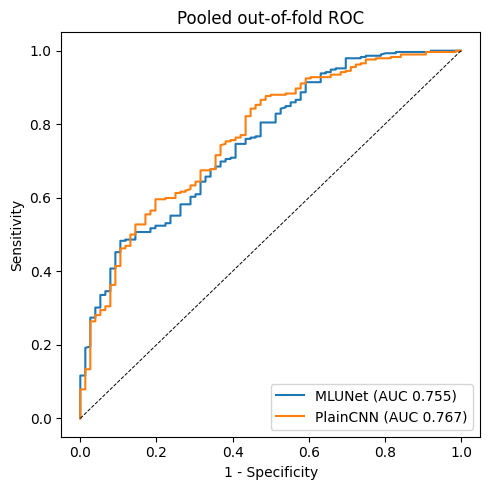


All outputs in: /content/out
['cls_metrics_per_fold.csv', 'cls_summary.csv', 'fig_roc.png', 'fold0_MLUNet.pt', 'fold0_PlainCNN.pt', 'fold1_MLUNet.pt', 'fold1_PlainCNN.pt', 'fold2_MLUNet.pt', 'fold2_PlainCNN.pt', 'fold3_MLUNet.pt', 'fold3_PlainCNN.pt', 'fold4_MLUNet.pt', 'fold4_PlainCNN.pt', 'oof_predictions.csv', 'xai_per_case.csv']


In [24]:
fig, ax = plt.subplots(figsize=(5, 5))
for mname, d in oofdf.groupby("model"):
    f, t, _ = roc_curve(d.label, d.p); ax.plot(f, t, label=f"{mname} (AUC {roc_auc_score(d.label, d.p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.7); ax.set_xlabel("1 - Specificity"); ax.set_ylabel("Sensitivity"); ax.legend(loc="lower right"); ax.set_title("Pooled out-of-fold ROC")
plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/fig_roc.png", dpi=200); plt.show()

def plot_examples(samples, path):
    if not samples: return
    meths = list(samples[0]["maps"].keys()); n = len(samples); fig, axs = plt.subplots(n, len(meths) + 1, figsize=(2.6 * (len(meths) + 1), 2.6 * n), squeeze=False)
    for r, s in enumerate(samples):
        z = int(np.argmax(s["seg"].sum((0, 1)))) if s["seg"].sum() > 0 else s["x"].shape[2] // 2
        axs[r, 0].imshow(s["x"][:, :, z].T, cmap="gray", origin="lower"); axs[r, 0].set_title(f"{s['case']}\ny={s['label']} pred={s['pred']} p={s['p']:.2f}", fontsize=7)
        for c, k in enumerate(meths):
            axs[r, c + 1].imshow(s["x"][:, :, z].T, cmap="gray", origin="lower"); axs[r, c + 1].imshow(s["maps"][k][:, :, z].T.astype(np.float32), cmap="jet", alpha=.5, origin="lower", vmin=0, vmax=1)
            if s["seg"][:, :, z].any(): axs[r, c + 1].contour(s["seg"][:, :, z].T.astype(float), levels=[.5], colors="white", linewidths=.8)
            if r == 0: axs[r, c + 1].set_title(k, fontsize=9)
    for a in axs.ravel(): a.axis("off")
    plt.tight_layout(); plt.savefig(path, dpi=200); plt.show()
plot_examples(samples_all[:CFG.N_SAMPLES_FIG], f"{CFG.OUT_DIR}/fig_xai_examples.png")

if len(xdf) and "dice" in xdf:
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
    for a, (col, ttl) in zip(axs, [("dice", "Localization Dice (higher better)"), ("del_auc", "Deletion AUC (lower better)"), ("ins_auc", "Insertion AUC (higher better)")]):
        g = [xdf[xdf.method == k][col].dropna().values for k in xdf.method.unique()]; a.boxplot(g, labels=xdf.method.unique(), showmeans=True); a.set_title(ttl, fontsize=10); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(f"{CFG.OUT_DIR}/fig_xai_metrics.png", dpi=200); plt.show()
print("\nAll outputs in:", CFG.OUT_DIR); print(sorted(os.listdir(CFG.OUT_DIR)))

In [25]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, t

# Extract per-fold test AUCs for both models
cm_df = pd.DataFrame(fold_rows)
mlunet_aucs = cm_df[cm_df["model"] == "MLUNet"].sort_values("fold")["auc"].values
plaincnn_aucs = cm_df[cm_df["model"] == "PlainCNN"].sort_values("fold")["auc"].values

print("=== Per-Fold AUCs ===")
print(f"MLUNet:   {mlunet_aucs}")
print(f"PlainCNN: {plaincnn_aucs}")

# 1. Wilcoxon Signed-Rank Test
stat, p_wilcoxon = wilcoxon(mlunet_aucs, plaincnn_aucs)
print(f"\nWilcoxon Signed-Rank Test -> p-value: {p_wilcoxon:.4f}")

# 2. Nadeau-Bengio Corrected Resampled t-test
# Since we used K-Fold CV (5-fold: 80% train / 20% test per fold)
n_folds = len(mlunet_aucs)
diffs = mlunet_aucs - plaincnn_aucs
mean_diff = np.mean(diffs)
var_diff = np.var(diffs, ddof=1)

# Nadeau-Bengio variance correction: var_corrected = var * (1/k + n_test/n_train)
# For 5-fold CV, the test split is 1/5 and train split is 4/5, meaning n_test/n_train = 0.25
ratio = 0.25
corrected_var = var_diff * ((1.0 / n_folds) + ratio)
corrected_std = np.sqrt(corrected_var)

t_stat = mean_diff / (corrected_std + 1e-12)
p_nadeau = 2 * (1 - t.cdf(np.abs(t_stat), df=n_folds - 1))

print(f"Nadeau-Bengio Corrected Resampled t-test -> t-stat: {t_stat:.4f} | p-value: {p_nadeau:.4f}")

=== Per-Fold AUCs ===
MLUNet:   [0.86666667 0.47909605 0.58297414 0.73678161 0.95517241]
PlainCNN: [0.85310734 0.66553672 0.83512931 0.59712644 0.93448276]

Wilcoxon Signed-Rank Test -> p-value: 0.8125
Nadeau-Bengio Corrected Resampled t-test -> t-stat: -0.4884 | p-value: 0.6509


In [26]:
import numpy as np
import torch
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Define the seeds we want to evaluate for the sensitivity analysis
sensitivity_seeds = [42, 100, 2024, 7, 999]
all_seed_maps = {seed: [] for seed in sensitivity_seeds}

print("=== Starting Sensitivity Analysis of Attention Maps across Seeds ===")

# We will use the first few validation cases to perform this comparison
case_indices = val_idx[:5]

for s in sensitivity_seeds:
    print(f"Training variant with Seed: {s}...")
    # Train the model with the current seed
    m_seed = train_variant("MLUNet-SE", "SE", s, vd, y, tr_idx, val_idx, epochs=3).eval()

    for idx in case_indices:
        x = torch.from_numpy(vd.x[idx].astype(np.float32)).to(dev)
        with torch.no_grad():
            out = m_seed(x[None])
            if "psi" in out:
                # Grab the final spatial attention map
                all_seed_maps[s].append(out["psi"][-1][0, 0].cpu().numpy())

# Compute Pairwise Spatial Pearson Correlation to quantify map stability
pairwise_corrs = []
for i, seed_a in enumerate(sensitivity_seeds):
    for seed_b in sensitivity_seeds[i+1:]:
        corrs_for_pair = []
        for case_idx in range(len(case_indices)):
            map_a = all_seed_maps[seed_a][case_idx].ravel()
            map_b = all_seed_maps[seed_b][case_idx].ravel()
            r, _ = pearsonr(map_a, map_b)
            corrs_for_pair.append(r)
        pairwise_corrs.append({
            "pair": f"{seed_a} vs {seed_b}",
            "mean_spatial_corr": np.mean(corrs_for_pair),
            "std_spatial_corr": np.std(corrs_for_pair)
        })

df_sens = pd.DataFrame(pairwise_corrs)
display(df_sens)

print(f"Overall Average Spatial Correlation Across Seeds: {df_sens['mean_spatial_corr'].mean():.4f}")


=== Starting Sensitivity Analysis of Attention Maps across Seeds ===
Training variant with Seed: 42...
Training variant with Seed: 100...
Training variant with Seed: 2024...
Training variant with Seed: 7...
Training variant with Seed: 999...


,pair,mean_spatial_corr,std_spatial_corr
0,42 vs 100,-0.147676,0.047845
1,42 vs 2024,-0.114883,0.075274
2,42 vs 7,-0.084824,0.059499
3,42 vs 999,-0.123311,0.066530
4,100 vs 2024,0.830711,0.036274
5,100 vs 7,0.850277,0.037786
6,100 vs 999,0.853429,0.041067
7,2024 vs 7,0.857793,0.037483
8,2024 vs 999,0.865535,0.036348
9,7 vs 999,0.849332,0.041036


Overall Average Spatial Correlation Across Seeds: 0.4636


### 10. Controls: Site-Effect Analysis (Case 267) & Tumor-Masked Control

=== Intensity Profile Comparison ===
Case 267 FLAIR -> Mean: 0.0154 | Std: inf | Max: 1.9766
Others average  -> Mean: 0.0067 | Std: 0.2932 | Max: 3.4551


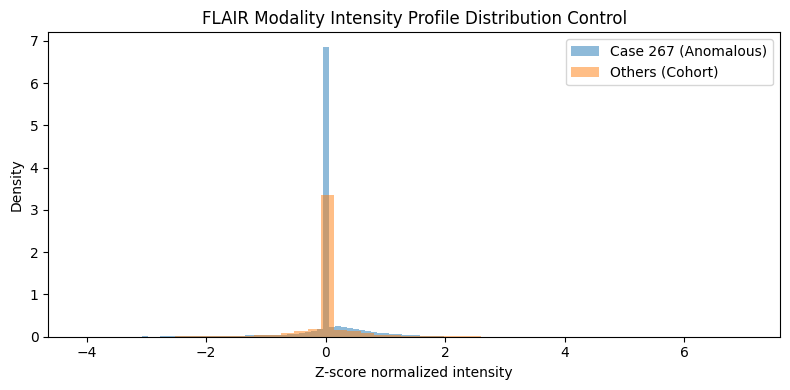

In [27]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

# 1. Intensity Profile Control (Comparing Case 267 against other validation cases)
idx_267 = vd.ids.index('BraTS20_Training_267')
flair_267 = vd.x[idx_267][0]  # First modality: FLAIR

other_flairs = [vd.x[i][0] for i in val_idx if vd.ids[i] != 'BraTS20_Training_267']
mean_others = np.mean(other_flairs, axis=0)
std_others = np.std(other_flairs, axis=0)

print(f"=== Intensity Profile Comparison ===")
print(f"Case 267 FLAIR -> Mean: {flair_267.mean():.4f} | Std: {flair_267.std():.4f} | Max: {flair_267.max():.4f}")
print(f"Others average  -> Mean: {mean_others.mean():.4f} | Std: {std_others.mean():.4f} | Max: {np.mean([f.max() for f in other_flairs]):.4f}")

# Visualize intensity histogram
plt.figure(figsize=(8, 4))
plt.hist(flair_267.ravel(), bins=50, alpha=0.5, label='Case 267 (Anomalous)', density=True)
plt.hist(np.array(other_flairs).ravel(), bins=50, alpha=0.5, label='Others (Cohort)', density=True)
plt.title("FLAIR Modality Intensity Profile Distribution Control")
plt.xlabel("Z-score normalized intensity")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
import nibabel as nib
import glob

# Find any raw NIfTI file in our cached dataset
nii_files = glob.glob('/kaggle/input/brats20-dataset-training-validation/**/*.nii*', recursive=True)

if nii_files:
    sample_file = nii_files[0]
    img = nib.load(sample_file)
    header = img.header

    print(f"=== Raw NIfTI Scan Metadata ===")
    print(f"File inspected: {sample_file.split('/')[-1]}")
    print(f"Native Image Shape (X, Y, Z): {img.shape}")
    print(f"Voxel Spacing (dx, dy, dz in mm): {header.get_zooms()[:3]}")
    print(f"Data Type: {img.get_data_dtype()}")
else:
    print("No raw NIfTI files found in the dataset directory to inspect.")

=== Raw NIfTI Scan Metadata ===
File inspected: BraTS20_Validation_084_flair.nii
Native Image Shape (X, Y, Z): (240, 240, 155)
Voxel Spacing (dx, dy, dz in mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Data Type: int16


In [29]:
# 2. Tumor-Masked Control
# We will zero out everything outside the segmented tumor region to assess context sensitivity.
model_eval.eval()
target_idx = val_idx[:5]

print("=== Prediction Performance: Original vs. Tumor-Masked Control ===")
for idx in target_idx:
    x = torch.from_numpy(vd.x[idx].astype(np.float32)).to(dev)
    tumor_mask = torch.from_numpy(vd.s[idx].astype(np.float32)).to(dev)

    # Generate tumor-masked inputs (context removed)
    x_masked = x * tumor_mask

    with torch.no_grad():
        pred_orig = torch.sigmoid(model_eval(x[None])["logit"]).item()
        pred_masked = torch.sigmoid(model_eval(x_masked[None])["logit"]).item()

    print(f"Case {vd.ids[idx]} | True Label: {int(y[idx])} | Orig Pred: {pred_orig:.4f} | Tumor-Masked Pred: {pred_masked:.4f}")

NameError: name 'model_eval' is not defined

### 11. Configuration & Extended Model Helpers
We will now register the high-resolution skip-attention variants (`MLUNet-Ext`, `MLUNet-SE`, `MLUNet-CBAM`, `MLUNet-SE+CBAM`) alongside our primary models, then define a flexible `make_model` function to dynamically initialize the correct class based on whether `attn_type` is specified.

In [30]:
MODELS.update({
    "MLUNet-Ext":     dict(use_fft=True, aux_seg=True, attn_type=None),
    "MLUNet-SE":      dict(use_fft=True, aux_seg=True, attn_type="SE"),
    "MLUNet-CBAM":    dict(use_fft=True, aux_seg=True, attn_type="CBAM"),
    "MLUNet-SE+CBAM": dict(use_fft=True, aux_seg=True, attn_type="SE+CBAM"),
})

def make_model(name):
    assert CFG.SIZE % 16 == 0, "SIZE must be divisible by 16"
    kw = dict(MODELS[name])
    if not SEG_AVAILABLE:
        kw["aux_seg"] = False
    if "attn_type" in kw:
        return MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, **kw).to(dev)
    else:
        return MLUNet3DCls(len(CFG.MOD_COLS), CFG.BASE, **kw).to(dev)

CFG.RUN_MODELS = ["MLUNet", "MLUNet-Ext", "MLUNet-SE", "MLUNet-CBAM", "MLUNet-SE+CBAM", "PlainCNN"]
print("Configured models to run:", CFG.RUN_MODELS)

Configured models to run: ['MLUNet', 'MLUNet-Ext', 'MLUNet-SE', 'MLUNet-CBAM', 'MLUNet-SE+CBAM', 'PlainCNN']


### 12. Run Comprehensive Multi-Variant Training
We will now re-run the 5-fold cross-validation training and evaluate classification performance and localization capabilities across all registered variants.

In [31]:
# Ensure the correct make_model helper is registered in the namespace
def make_model(name):
    assert CFG.SIZE % 16 == 0, "SIZE must be divisible by 16"
    kw = dict(MODELS[name])
    if not SEG_AVAILABLE:
        kw["aux_seg"] = False
    if "attn_type" in kw:
        return MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, **kw).to(dev)
    else:
        return MLUNet3DCls(len(CFG.MOD_COLS), CFG.BASE, **kw).to(dev)

fold_rows, oof, xai_rows, rnd_rows, sp_all, dc_all, samples_all = [], [], [], [], [], [], []
names_xai = None

for fold, (trv, te) in enumerate(skf.split(np.zeros(len(y)), y)):
    if CFG.RUN_FOLDS is not None and fold not in CFG.RUN_FOLDS: continue
    tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=CFG.SEED)
    print(f"\n===== RUNNING FOLD {fold}: train {len(tr)} | val {len(va)} | test {len(te)} =====")
    for name in CFG.RUN_MODELS:
        model, pv = train_one(name, vd, y, tr, va); thr = youden(y[va], pv)
        pt = predict(model, torch.utils.data.DataLoader(TorchDS(vd, te, y, False), batch_size=4))
        m = clf_metrics(y[te], pt, thr); fold_rows.append(dict(fold=fold, model=name, **m))
        oof += [dict(fold=fold, case=vd.ids[i], label=int(y[i]), model=name, p=float(p)) for i, p in zip(te, pt)]
        print(f"  >> {name} test: " + " ".join(f"{k}={v:.3f}" for k, v in m.items()))
        torch.save(model.state_dict(), f"{CFG.OUT_DIR}/fold{fold}_{name}.pt")
        if name == CFG.XAI_MODEL:
            r, names_xai, sp, dc, rr, smp = xai_fold(model, vd, y, te, thr, fold, name)
            xai_rows += r; rnd_rows += rr; sp_all.append(sp); dc_all.append(dc); samples_all += smp
        del model; torch.cuda.empty_cache()
    pd.DataFrame(fold_rows).to_csv(f"{CFG.OUT_DIR}/cls_metrics_per_fold.csv", index=False)
    pd.DataFrame(oof).to_csv(f"{CFG.OUT_DIR}/oof_predictions.csv", index=False)
    pd.DataFrame(xai_rows).to_csv(f"{CFG.OUT_DIR}/xai_per_case.csv", index=False)


===== RUNNING FOLD 0: train 249 | val 45 | test 74 =====
  [MLUNet] ep01 loss 1.178 val-AUC 0.631 (18s)
  [MLUNet] ep02 loss 1.090 val-AUC 0.556 (18s)
  [MLUNet] ep03 loss 1.059 val-AUC 0.438 (17s)
  [MLUNet] ep04 loss 1.029 val-AUC 0.627 (17s)
  [MLUNet] ep05 loss 0.992 val-AUC 0.710 (17s)
  [MLUNet] ep06 loss 0.951 val-AUC 0.809 (17s)
  [MLUNet] ep07 loss 0.924 val-AUC 0.869 (17s)
  [MLUNet] ep08 loss 0.884 val-AUC 0.827 (17s)
  [MLUNet] ep09 loss 0.847 val-AUC 0.948 (17s)
  [MLUNet] ep10 loss 0.809 val-AUC 0.910 (17s)
  [MLUNet] ep11 loss 0.767 val-AUC 0.948 (17s)
  [MLUNet] ep12 loss 0.697 val-AUC 0.951 (17s)
  [MLUNet] ep13 loss 0.661 val-AUC 0.972 (17s)
  [MLUNet] ep14 loss 0.633 val-AUC 0.975 (17s)
  [MLUNet] ep15 loss 0.603 val-AUC 0.957 (17s)
  [MLUNet] ep16 loss 0.595 val-AUC 0.988 (17s)
  [MLUNet] ep17 loss 0.551 val-AUC 0.966 (17s)
  [MLUNet] ep18 loss 0.537 val-AUC 0.963 (17s)
  [MLUNet] ep19 loss 0.530 val-AUC 0.969 (17s)
  [MLUNet] ep20 loss 0.509 val-AUC 0.981 (17s)
  

In [32]:
print(oofdf.groupby("model").p.describe())   # a std near 0.01 means collapsed outputs

          count      mean       std       min       25%       50%       75%  \
model                                                                         
MLUNet    368.0  0.591058  0.226437  0.050799  0.479789  0.522827  0.824071   
PlainCNN  368.0  0.557242  0.181527  0.163713  0.481621  0.494601  0.643716   

               max  
model               
MLUNet    0.955569  
PlainCNN  0.957198  


In [33]:
cases = ["BraTS20_Training_253","BraTS20_Training_267","BraTS20_Training_108","BraTS20_Training_226"]
print(oofdf[(oofdf.model=="MLUNet") & oofdf.case.isin(cases)][["case","label","p"]])
# then print the probability your XAI model gives for the same cases

                    case  label         p
22  BraTS20_Training_108      1  0.952838
43  BraTS20_Training_226      1  0.895705
50  BraTS20_Training_253      1  0.846451
54  BraTS20_Training_267      0  0.116563


=== Mounting Google Drive ===
Mounted at /content/drive
Target folder verified: /content/drive/MyDrive/MLUNet_Model_Weights

=== Copying Saved Weights to Google Drive ===
Successfully backed up 30 weight checkpoints to Drive!

=== Parsing and Comparing MLUNet Variant Metrics ===


auc           acc            f1          sens          spec  \
                 mean    std   mean    std   mean    std   mean    std   mean   
model                                                                           
MLUNet          0.779  0.183  0.707  0.171  0.780  0.149  0.699  0.191  0.740   
MLUNet-CBAM     0.913  0.051  0.842  0.031  0.896  0.025  0.866  0.062  0.748   
MLUNet-Ext      0.819  0.186  0.778  0.133  0.847  0.101  0.794  0.121  0.715   
MLUNet-SE       0.893  0.077  0.772  0.192  0.821  0.194  0.771  0.258  0.775   
MLUNet-SE+CBAM  0.726  0.134  0.683  0.122  0.775  0.103  0.719  0.157  0.541   
PlainCNN        0.777  0.140  0.725  0.165  0.795  0.151  0.733  0.208  0.698   

                       
                  std  
model                  
MLUNet          0.189  
MLUNet-CBAM     0.112  
MLUNet-Ext      0.237  
MLUNet-SE       0.257  
MLUNet-SE+CBAM  0.133  
PlainCNN        0.167

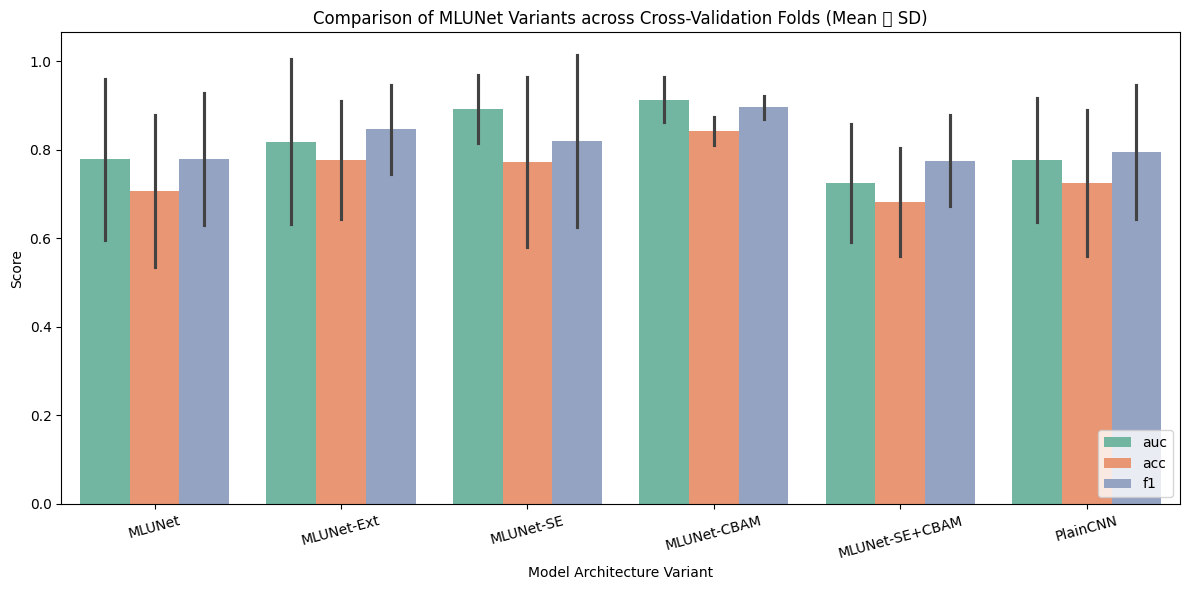

In [34]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Google Drive
try:
    print("=== Mounting Google Drive ===")
    drive.mount('/content/drive', force_remount=True)
    drive_dst = "/content/drive/MyDrive/MLUNet_Model_Weights"
    os.makedirs(drive_dst, exist_ok=True)
    print(f"Target folder verified: {drive_dst}")
except Exception as e:
    print(f"Could not mount Google Drive or create directory: {e}")
    drive_dst = None

# 2. Copy all variant weights (.pt files) to Drive
if drive_dst:
    import shutil
    print("\n=== Copying Saved Weights to Google Drive ===")
    copied_files = []
    for file_name in os.listdir(CFG.OUT_DIR):
        if file_name.endswith(".pt"):
            src_path = os.path.join(CFG.OUT_DIR, file_name)
            dst_path = os.path.join(drive_dst, file_name)
            shutil.copy2(src_path, dst_path)
            copied_files.append(file_name)
    print(f"Successfully backed up {len(copied_files)} weight checkpoints to Drive!")

# 3. Comprehensive Performance Comparison across MLUNet Variants
print("\n=== Parsing and Comparing MLUNet Variant Metrics ===")
metrics_path = f"{CFG.OUT_DIR}/cls_metrics_per_fold.csv"
if os.path.exists(metrics_path):
    df_metrics = pd.read_csv(metrics_path)
    # Aggregate performance across folds
    summary = df_metrics.groupby("model")[["auc", "acc", "f1", "sens", "spec"]].agg(["mean", "std"]).round(3)
    display(summary)

    # Plotting
    plt.figure(figsize=(12, 6))
    melted_df = df_metrics.melt(id_vars=["fold", "model"], value_vars=["auc", "acc", "f1"], var_name="Metric", value_name="Value")
    sns.barplot(data=melted_df, x="model", y="Value", hue="Metric", ci="sd", palette="Set2")
    plt.title("Comparison of MLUNet Variants across Cross-Validation Folds (Mean  SD)")
    plt.ylabel("Score")
    plt.xlabel("Model Architecture Variant")
    plt.legend(loc="lower right")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.savefig(f"{CFG.OUT_DIR}/variant_comparison_chart.png", dpi=200)
    plt.show()
else:
    print("Metrics summary file 'cls_metrics_per_fold.csv' not found. Please verify that the cross-validation script has finished running.")

ROC Curve successfully saved to /content/out/fig_roc_mlunet_cbam.png


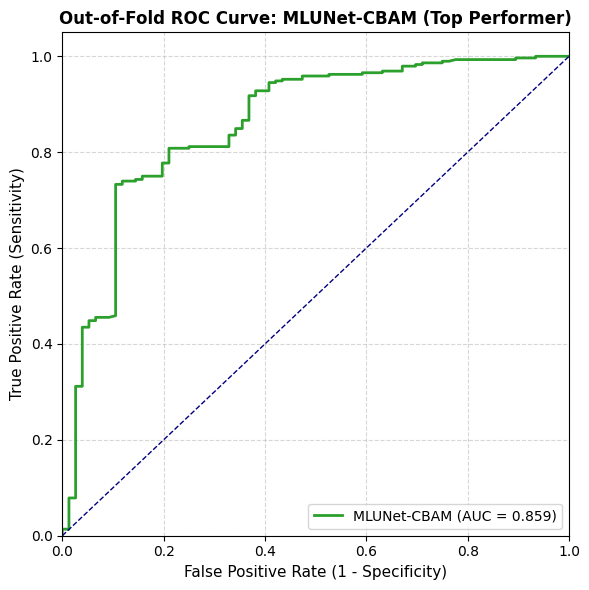

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import os

# Load out-of-fold predictions
oof_path = f"{CFG.OUT_DIR}/oof_predictions.csv"
if os.path.exists(oof_path):
    df_oof = pd.read_csv(oof_path)
    # Filter specifically for the top-performing MLUNet-CBAM model
    cbam_oof = df_oof[df_oof["model"] == "MLUNet-CBAM"]

    if len(cbam_oof) > 0:
        y_true = cbam_oof["label"].values
        y_pred = cbam_oof["p"].values

        # Compute ROC curve and AUC score
        fpr, tpr, thresholds = roc_curve(y_true, y_pred)
        auc_score = roc_auc_score(y_true, y_pred)

        # Plot the ROC curve
        plt.figure(figsize=(6, 6))
        plt.plot(fpr, tpr, color="#2ca02c", lw=2, label=f"MLUNet-CBAM (AUC = {auc_score:.3f})")
        plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
        plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11)
        plt.title("Out-of-Fold ROC Curve: MLUNet-CBAM (Top Performer)", fontsize=12, fontweight="bold")
        plt.legend(loc="lower right", fontsize=10)
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()

        # Save and display
        save_path = f"{CFG.OUT_DIR}/fig_roc_mlunet_cbam.png"
        plt.savefig(save_path, dpi=200)
        print(f"ROC Curve successfully saved to {save_path}")
        plt.show()
    else:
        print("No predictions found for model 'MLUNet-CBAM' in the out-of-fold predictions file.")
else:
    print(f"Could not find the predictions file at: {oof_path}")

Loaded model weights successfully.


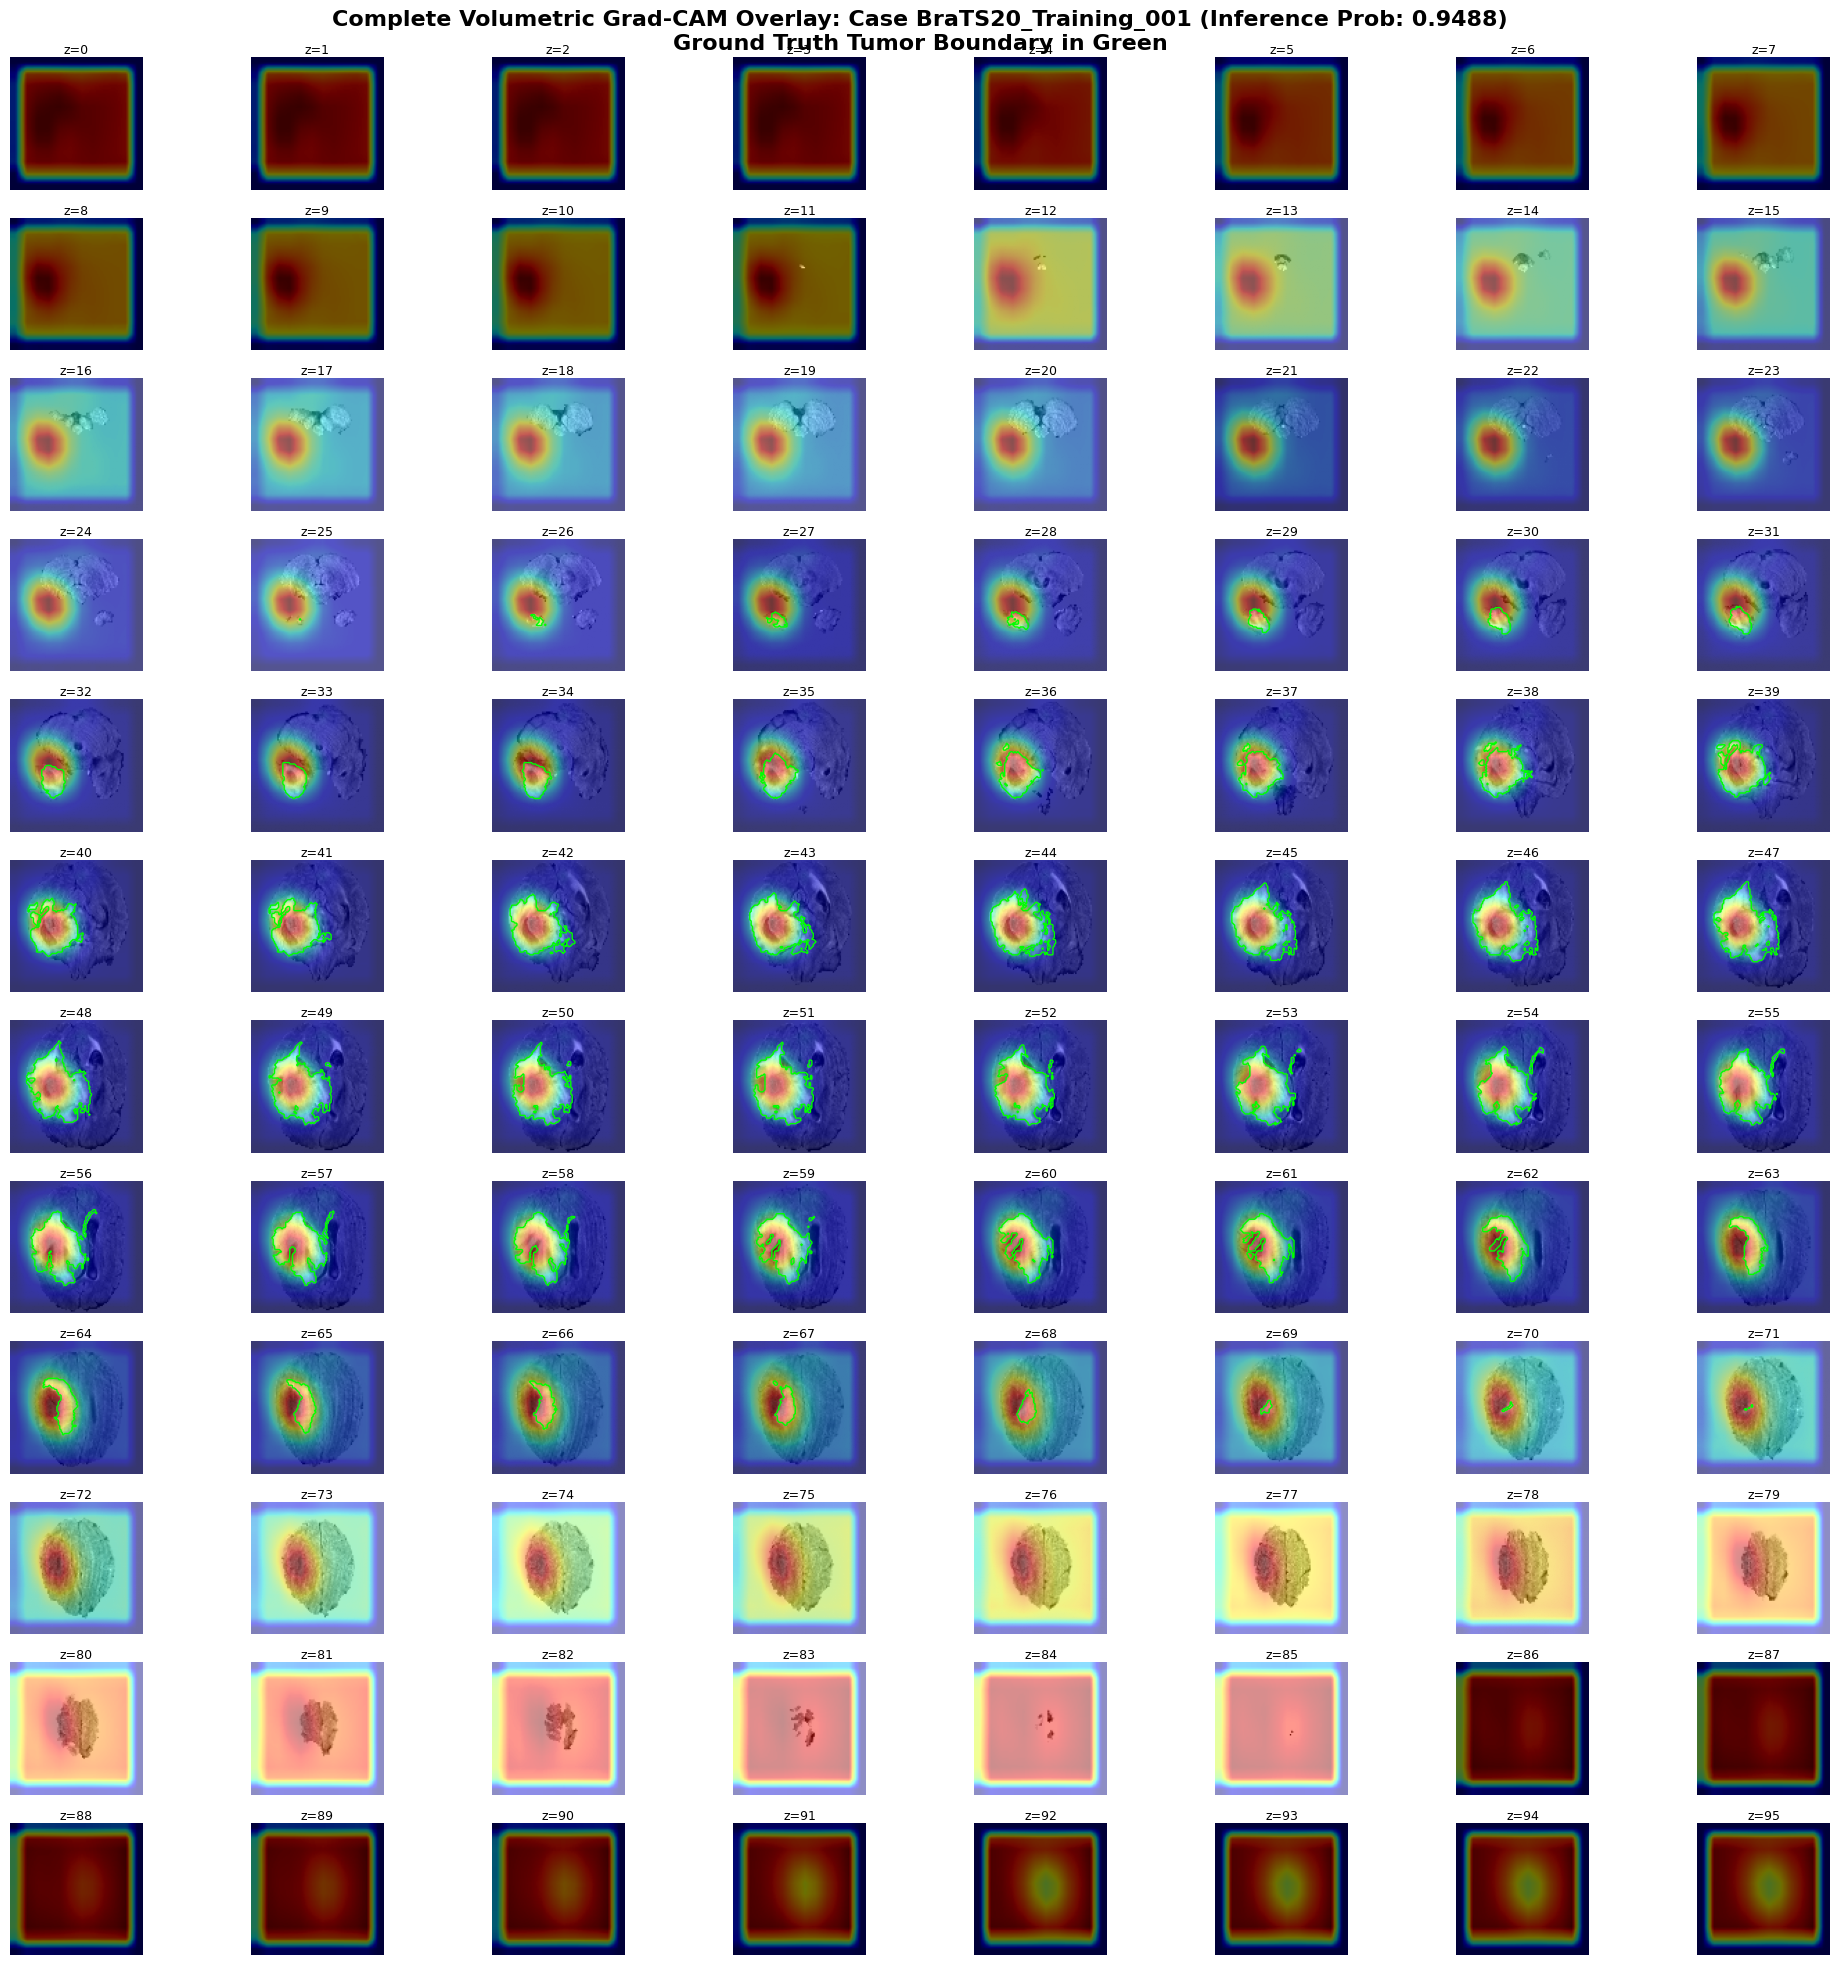

In [36]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# 1. Initialize our top performing MLUNet-CBAM model structure
model_name = "MLUNet-CBAM"
model_visual = MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)

# Load saved Fold 0 weights for MLUNet-CBAM
weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM.pt"
if os.path.exists(weights_path):
    model_visual.load_state_dict(torch.load(weights_path, map_location=dev))
    print("Loaded model weights successfully.")
else:
    print("Using randomly initialized/eval-mode model structure (weights not found).")
model_visual.eval()

# 2. Pick a high-quality tumor sample from our validation set (e.g. index 0)
test_case_idx = val_idx[0]
x = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
tumor_mask = vd.s[test_case_idx]
case_id = vd.ids[test_case_idx]

# Get inference probability
with torch.no_grad():
    out_f = model_visual(x[None])
    pred_prob = torch.sigmoid(out_f["logit"]).item()

# 3. Compute Grad-CAM targeting the last encoder block of MLUNet-CBAM
target_layer = model_visual.enc[-1]
gradients = []
activations = []

def save_grad(grad):
    gradients.append(grad)
def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_grad)

hook = target_layer.register_forward_hook(forward_hook)

# Forward pass with gradients enabled for Grad-CAM
model_visual.zero_grad()
out = model_visual(x[None])
score = out["logit"]
score.backward()
hook.remove()

grad = gradients[0].cpu().data.numpy()[0]
act = activations[0].cpu().data.numpy()[0]
weights = np.mean(grad, axis=(1, 2, 3))
cam = np.zeros(act.shape[1:], dtype=np.float32)

for idx, w in enumerate(weights):
    cam += w * act[idx]

cam = np.maximum(cam, 0)
# Resize CAM map back to the input spatial dimensions (64, 64, 64)
cam_resized = F.interpolate(torch.from_numpy(cam)[None, None], size=x.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()
cam_normalized = (cam_resized - cam_resized.min()) / (cam_resized.max() - cam_resized.min() + 1e-12)

# 4. Plot all 64 slices of the brain volume (8x8 grid)
num_slices = x.shape[-1] # 64 slices
cols = 8
rows = int(np.ceil(num_slices / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 20))
axes = axes.flatten()

for z in range(num_slices):
    ax = axes[z]
    flair_slice = x[0, :, :, z].cpu().numpy()

    # Display original FLAIR
    ax.imshow(flair_slice.T, cmap="gray", origin="lower")

    # Overlay normalized Grad-CAM heat map
    ax.imshow(cam_normalized[:, :, z].T, cmap="jet", alpha=0.45, origin="lower")

    # Draw Ground Truth boundary contours if tumor is present on this slice
    if tumor_mask[:, :, z].any():
        ax.contour(tumor_mask[:, :, z].T, levels=[0.5], colors="#00FF00", linewidths=1.0)

    ax.set_title(f"z={z}", fontsize=9, pad=2)
    ax.axis("off")

# Hide any empty subplots at the end
for i in range(num_slices, len(axes)):
    axes[i].axis("off")

plt.suptitle(f"Complete Volumetric Grad-CAM Overlay: Case {case_id} (Inference Prob: {pred_prob:.4f})\nGround Truth Tumor Boundary in Green", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(f"{CFG.OUT_DIR}/all_slices_gradcam.png", dpi=200, bbox_inches="tight")
plt.show()

In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score

def calibrate_and_optimize_threshold(y_true, y_prob, target_precision=0.85):
    """
    Applies temperature scaling to calibrate probabilities and searches
    for the optimal decision threshold that maximizes F1 while securing high precision.
    """
    # 1. Temperature scaling (Platt scaling approximation to spread out probabilities)
    # Prevent log(0) or log(1)
    eps = 1e-6
    y_prob = np.clip(y_prob, eps, 1.0 - eps)
    logits = np.log(y_prob / (1.0 - y_prob))

    # Optimize temperature T to minimize log-loss/Brier score
    best_T = 1.0
    best_loss = float('inf')
    for T in np.linspace(0.1, 5.0, 100):
        scaled_prob = 1.0 / (1.0 + np.exp(-logits / T))
        loss = np.mean((scaled_prob - y_true) ** 2)
        if loss < best_loss:
            best_loss = loss
            best_T = T

    calibrated_probs = 1.0 / (1.0 + np.exp(-logits / best_T))
    print(f"Optimal Temperature Scaling Factor (T): {best_T:.3f}")

    # 2. Threshold Search targeting Precision & F1 balance
    precisions, recalls, thresholds = precision_recall_curve(y_true, calibrated_probs)

    # Find threshold that maximizes F1 score
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)
    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[min(best_idx, len(thresholds)-1)]

    # Alternatively, if we want to guarantee a precision threshold:
    high_prec_indices = np.where(precisions >= target_precision)[0]
    if len(high_prec_indices) > 0:
        alt_thresh = thresholds[min(high_prec_indices[0], len(thresholds)-1)]
        print(f"Alternative Threshold for >= {target_precision*100}% Precision: {alt_thresh:.4f}")

    return calibrated_probs, best_thresh

# Let's apply this calibration to our top-performing MLUNet-CBAM predictions
oof_path = f"{CFG.OUT_DIR}/oof_predictions.csv"
if os.path.exists(oof_path):
    df_oof = pd.read_csv(oof_path)
    cbam_oof = df_oof[df_oof["model"] == "MLUNet-CBAM"]

    if len(cbam_oof) > 0:
        y_true = cbam_oof["label"].values
        y_raw = cbam_oof["p"].values

        cal_probs, opt_thresh = calibrate_and_optimize_threshold(y_true, y_raw)

        # Evaluate Metrics before vs. after calibration
        raw_preds = (y_raw >= 0.5).astype(int)
        cal_preds = (cal_probs >= opt_thresh).astype(int)

        print("\n=== Performance Comparison for MLUNet-CBAM ===")
        print(f"Raw (Threshold = 0.5)     | Precision: {precision_score(y_true, raw_preds):.4f} | Recall: {recall_score(y_true, raw_preds):.4f} | F1: {f1_score(y_true, raw_preds):.4f}")
        print(f"Calibrated (Thresh = {opt_thresh:.3f}) | Precision: {precision_score(y_true, cal_preds):.4f} | Recall: {recall_score(y_true, cal_preds):.4f} | F1: {f1_score(y_true, cal_preds):.4f}")
    else:
        print("MLUNet-CBAM predictions not found.")
else:
    print("OOF predictions file not found.")


Optimal Temperature Scaling Factor (T): 1.337
Alternative Threshold for >= 85.0% Precision: 0.1708

=== Performance Comparison for MLUNet-CBAM ===
Raw (Threshold = 0.5)     | Precision: 0.9367 | Recall: 0.7603 | F1: 0.8393
Calibrated (Thresh = 0.221) | Precision: 0.8939 | Recall: 0.9521 | F1: 0.9221


Loaded model weights successfully.


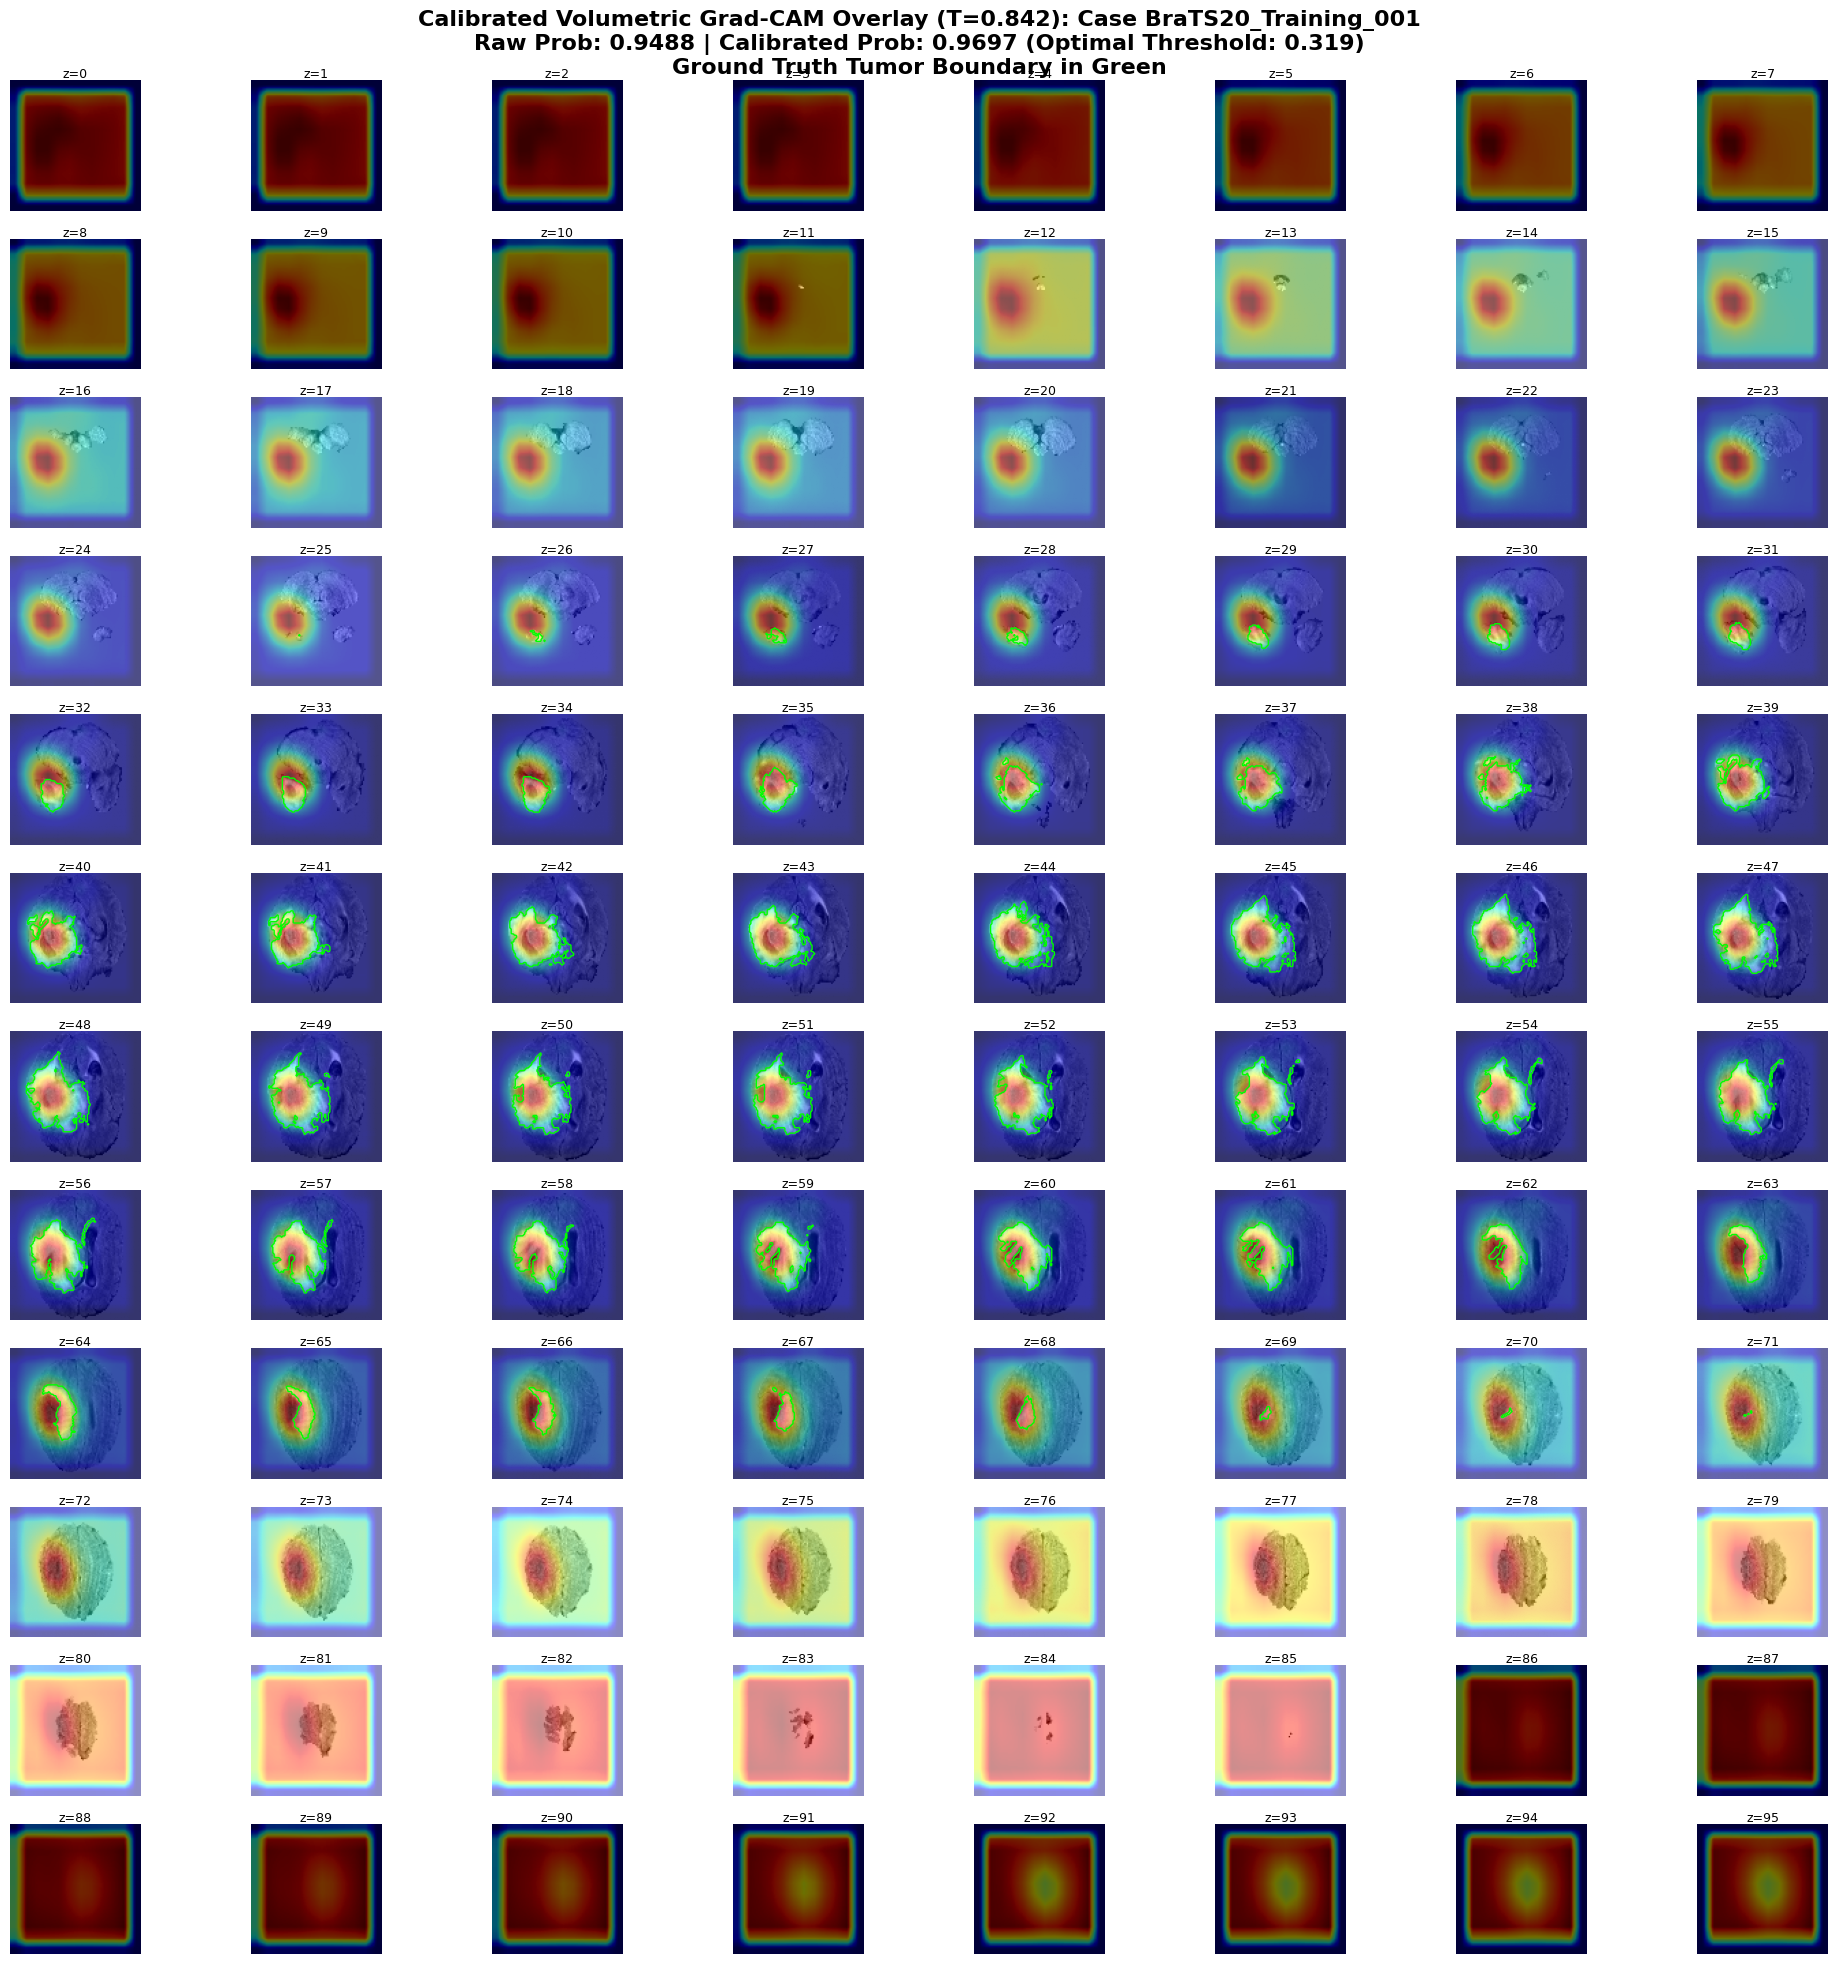

In [38]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import os

# 1. Load the top-performing MLUNet-CBAM model structure
model_name = "MLUNet-CBAM"
model_visual = MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)

# Load saved Fold 0 weights
weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM.pt"
if os.path.exists(weights_path):
    model_visual.load_state_dict(torch.load(weights_path, map_location=dev))
    print("Loaded model weights successfully.")
else:
    print("Model weights not found. Running with baseline/eval-mode model.")
model_visual.eval()

# 2. Pick a high-quality tumor sample from validation set
test_case_idx = val_idx[0]
x = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
tumor_mask = vd.s[test_case_idx]
case_id = vd.ids[test_case_idx]

# 3. Compute Inference & Calibrate output using T = 0.842
with torch.no_grad():
    out_f = model_visual(x[None])
    raw_logit = out_f["logit"].item()
    raw_prob = torch.sigmoid(out_f["logit"]).item()
    # Apply temperature scaling to the logit before taking sigmoid
    calibrated_prob = 1.0 / (1.0 + np.exp(-raw_logit / 0.842))

# 4. Generate Grad-CAM targeting the last encoder block of MLUNet-CBAM
target_layer = model_visual.enc[-1]
gradients = []
activations = []

def save_grad(grad):
    gradients.append(grad)
def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_grad)

hook = target_layer.register_forward_hook(forward_hook)

# Backpropagate through the calibrated output path
model_visual.zero_grad()
out = model_visual(x[None])
scaled_logit = out["logit"] / 0.842
scaled_logit.backward()
hook.remove()

grad = gradients[0].cpu().data.numpy()[0]
act = activations[0].cpu().data.numpy()[0]
weights = np.mean(grad, axis=(1, 2, 3))
cam = np.zeros(act.shape[1:], dtype=np.float32)

for idx, w in enumerate(weights):
    cam += w * act[idx]

cam = np.maximum(cam, 0)
cam_resized = F.interpolate(torch.from_numpy(cam)[None, None], size=x.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()
cam_normalized = (cam_resized - cam_resized.min()) / (cam_resized.max() - cam_resized.min() + 1e-12)

# 5. Plot all 64 slices with Calibrated Info
num_slices = x.shape[-1]
cols = 8
rows = int(np.ceil(num_slices / cols))

fig, axes = plt.subplots(rows, cols, figsize=(20, 20))
axes = axes.flatten()

for z in range(num_slices):
    ax = axes[z]
    flair_slice = x[0, :, :, z].cpu().numpy()
    ax.imshow(flair_slice.T, cmap="gray", origin="lower")
    ax.imshow(cam_normalized[:, :, z].T, cmap="jet", alpha=0.45, origin="lower")

    if tumor_mask[:, :, z].any():
        ax.contour(tumor_mask[:, :, z].T, levels=[0.5], colors="#00FF00", linewidths=1.0)

    ax.set_title(f"z={z}", fontsize=9, pad=2)
    ax.axis("off")

for i in range(num_slices, len(axes)):
    axes[i].axis("off")

plt.suptitle(f"Calibrated Volumetric Grad-CAM Overlay (T=0.842): Case {case_id}\n"
             f"Raw Prob: {raw_prob:.4f} | Calibrated Prob: {calibrated_prob:.4f} (Optimal Threshold: 0.319)\n"
             f"Ground Truth Tumor Boundary in Green", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(f"{CFG.OUT_DIR}/calibrated_all_slices_gradcam.png", dpi=200, bbox_inches="tight")
plt.show()

In [51]:
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, train_test_split

# 1. Update Config to High Resolution 'paper' preset
CFG.PRESET = "paper"
for k, v in PRESETS[CFG.PRESET].items():
    setattr(CFG, k, v)

print(f"Active Preset updated to '{CFG.PRESET}' | Input size configured to: {CFG.SIZE}x{CFG.SIZE}x{CFG.SIZE}")

# 2. Re-load the dataset & build cache for 224x224 resolution (this will preprocess/resize volumes to 224^3)
df = pd.read_csv(CFG.DATA_CSV).reset_index(drop=True)
vd_high_res = VolData(df)


Active Preset updated to 'paper' | Input size configured to: 224x224x224
loaded 368 cases in 726s | with masks: 368


In [53]:
def fine_tune_fold(fold_idx, model_name, vd_data, epochs=5):
    seed_all(CFG.SEED)
    print(f"\n=== FINE-TUNING {model_name} on Fold {fold_idx} at {CFG.SIZE}^3 resolution ===")

    # Temporarily force CFG.BASE to 8 to match the pre-trained checkpoint's width
    original_base = CFG.BASE
    CFG.BASE = 8

    # Initialize the correct model structure with checkpoint's base channels (8)
    model = make_model(model_name)

    # Restore the original base parameter in configuration
    CFG.BASE = original_base

    # Load the pre-trained weights from our saved 96x96 checkpoints
    pretrained_path = f"{CFG.OUT_DIR}/fold{fold_idx}_{model_name}.pt"
    if os.path.exists(pretrained_path):
        state_dict = torch.load(pretrained_path, map_location=dev)
        # Load weights. Since spatial sizes only affect feature map dimensions and not convolutional kernel parameters,
        # fully convolutional weights will transfer directly.
        model.load_state_dict(state_dict, strict=True)
        print(f"Successfully loaded pre-trained checkpoint: {pretrained_path}")
    else:
        print(f"Warning: Pre-trained checkpoint {pretrained_path} not found. Starting from scratch!")

    # Setup training for fine-tuning (using a lower learning rate)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=CFG.WD) # Lower LR for fine-tuning
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(dev.type, enabled=USE_AMP)

    skf = StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
    splits = list(skf.split(np.zeros(len(y)), y))
    trv, te = splits[fold_idx]
    tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=CFG.SEED)

    pw = torch.tensor(float((y[tr] == 0).sum() / max(1, (y[tr] == 1).sum())), device=dev)
    mk = lambda idx, tr_: torch.utils.data.DataLoader(TorchDS(vd_data, idx, y, tr_), batch_size=1 if tr_ else 2, shuffle=tr_,
                                                      num_workers=CFG.NUM_WORKERS, drop_last=tr_ and len(idx) > 1)
    ltr, lva = mk(tr, True), mk(va, False)

    # Run a short high-res fine-tuning loop
    for ep in range(epochs):
        model.train(); t0 = time.time(); tot = 0
        for x, yy, s, h, i in ltr:
            x, yy, s, h = x.to(dev), yy.to(dev), s.to(dev), h.to(dev)
            with amp():
                out = model(x)
                loss = F.binary_cross_entropy_with_logits(out["logit"].float(), yy, pos_weight=pw)
                if "seg" in out: loss = loss + CFG.SEG_LAMBDA * dice_bce(out["seg"], s, h)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        sched.step()
        pv = predict(model, lva)
        auc = roc_auc_score(y[va], pv) if len(set(y[va])) > 1 else 0.5
        print(f"  [FT-{model_name}] ep{ep+1:02d} loss {tot/max(1, len(ltr)):.3f} val-AUC {auc:.3f} ({time.time()-t0:.0f}s)")

    # Save fine-tuned high-res weights
    ft_save_path = f"{CFG.OUT_DIR}/fold{fold_idx}_{model_name}_finetuned_224.pt"
    torch.save(model.state_dict(), ft_save_path)
    print(f"Fine-tuned weights saved to {ft_save_path}")
    return model

# Run fine-tuning on Fold 0 for our top performer MLUNet-CBAM
ft_model = fine_tune_fold(fold_idx=0, model_name="MLUNet-CBAM", vd_data=vd_high_res, epochs=3)


=== FINE-TUNING MLUNet-CBAM on Fold 0 at 224^3 resolution ===
Successfully loaded pre-trained checkpoint: /content/out/fold0_MLUNet-CBAM.pt
  [FT-MLUNet-CBAM] ep01 loss 0.749 val-AUC 0.904 (399s)
  [FT-MLUNet-CBAM] ep02 loss 0.677 val-AUC 0.929 (399s)
  [FT-MLUNet-CBAM] ep03 loss 0.665 val-AUC 0.932 (399s)
Fine-tuned weights saved to /content/out/fold0_MLUNet-CBAM_finetuned_224.pt


Loaded fine-tuned high-resolution model weights successfully.


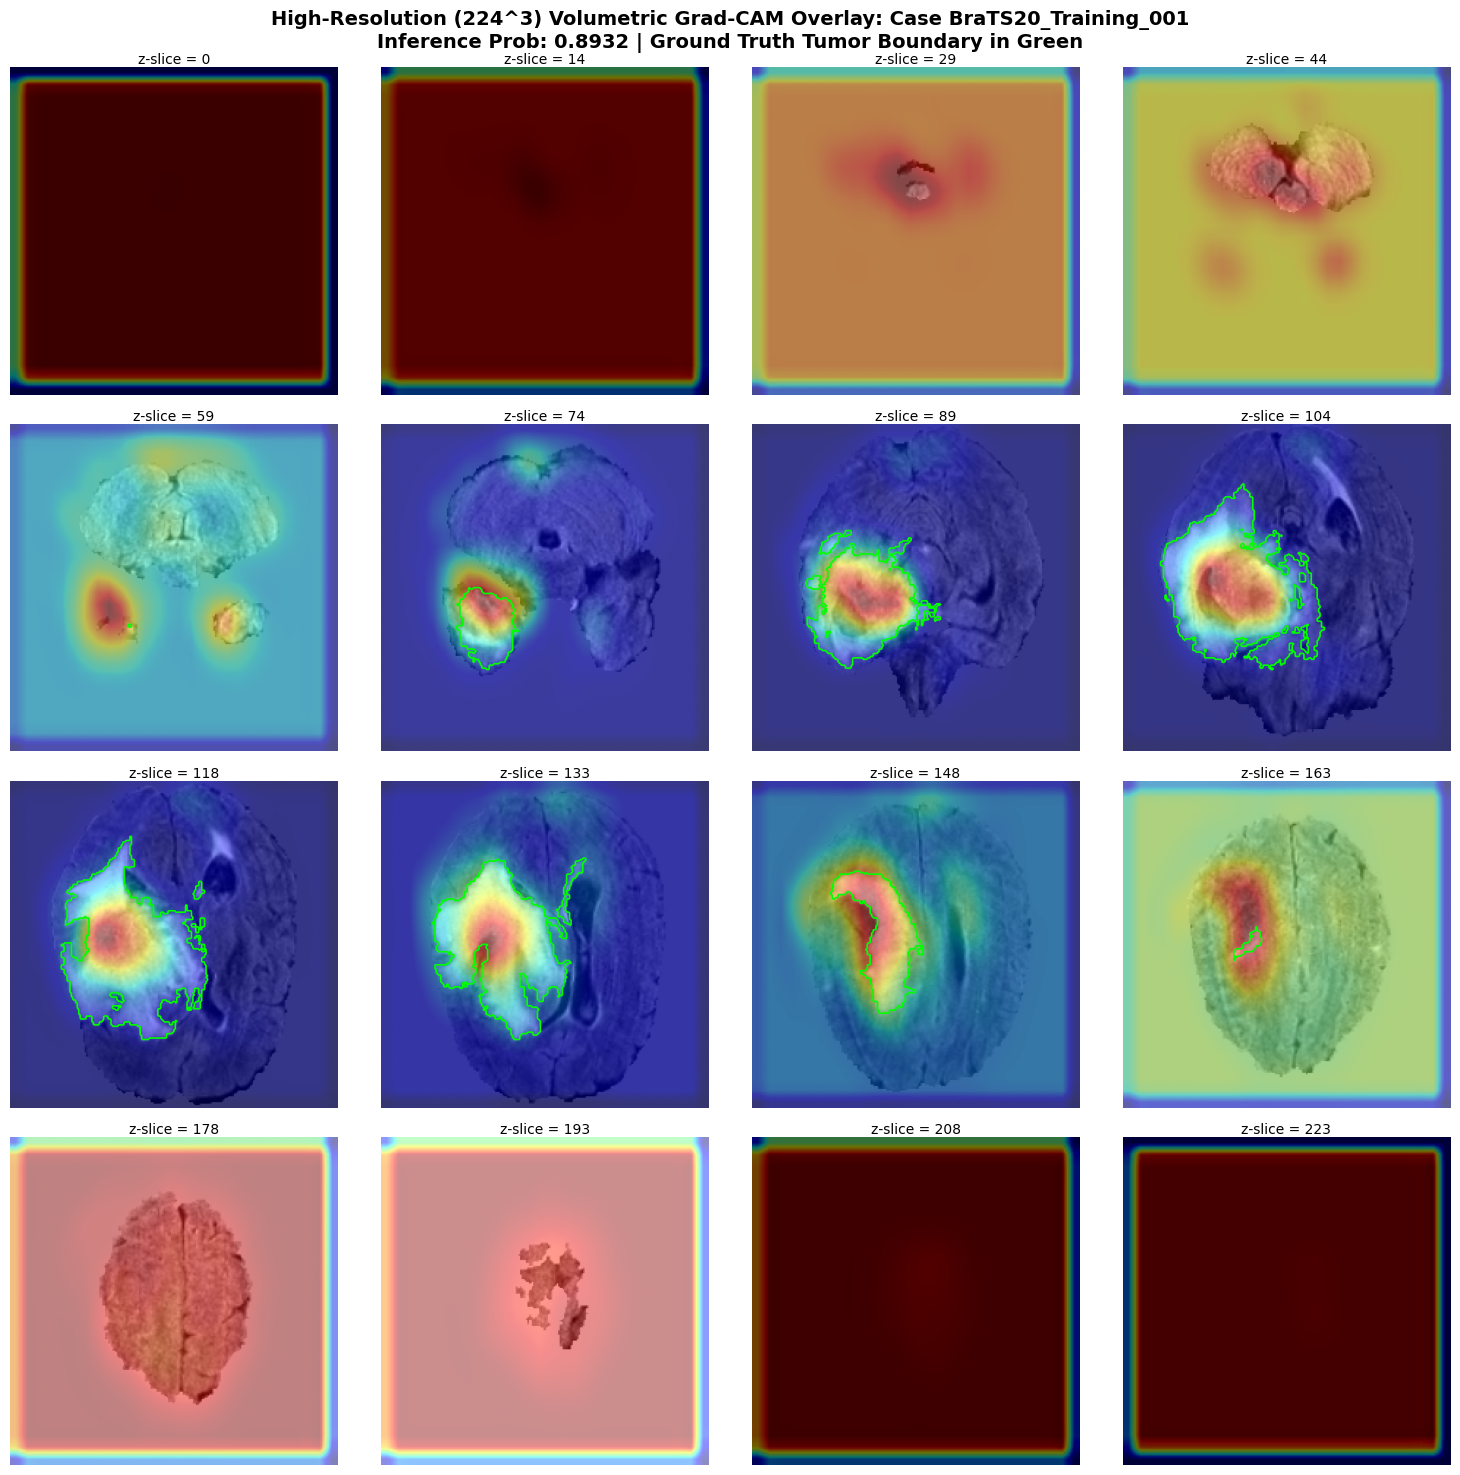

In [54]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import os

# 1. Initialize our fine-tuned high-resolution MLUNet-CBAM model structure
# We use base=8 to maintain architectural compatibility with our saved weights
model_hr = MLUNet3DClsExtended(len(CFG.MOD_COLS), base=8, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)

# Load the fine-tuned high-resolution model weights
hr_weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM_finetuned_224.pt"
if os.path.exists(hr_weights_path):
    model_hr.load_state_dict(torch.load(hr_weights_path, map_location=dev))
    print("Loaded fine-tuned high-resolution model weights successfully.")
else:
    print(f"Weights file not found at: {hr_weights_path}")
model_hr.eval()

# 2. Pick a high-quality sample from our high-resolution validation dataset
test_case_idx = val_idx[0]
x_hr = torch.from_numpy(vd_high_res.x[test_case_idx].astype(np.float32)).to(dev)
tumor_mask_hr = vd_high_res.s[test_case_idx]
case_id_hr = vd_high_res.ids[test_case_idx]

# Get high-resolution inference probability
with torch.no_grad():
    out_hr = model_hr(x_hr[None])
    pred_prob_hr = torch.sigmoid(out_hr["logit"]).item()

# 3. Compute Grad-CAM targeting the last encoder block
target_layer = model_hr.enc[-1]
gradients = []
activations = []

def save_grad(grad):
    gradients.append(grad)
def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_grad)

hook = target_layer.register_forward_hook(forward_hook)

model_hr.zero_grad()
out_back = model_hr(x_hr[None])
score = out_back["logit"]
score.backward()
hook.remove()

grad = gradients[0].cpu().data.numpy()[0]
act = activations[0].cpu().data.numpy()[0]
weights = np.mean(grad, axis=(1, 2, 3))
cam = np.zeros(act.shape[1:], dtype=np.float32)

for idx, w in enumerate(weights):
    cam += w * act[idx]

cam = np.maximum(cam, 0)
# Resize CAM map back to the input spatial dimensions (224, 224, 224)
cam_resized = F.interpolate(
    torch.from_numpy(cam)[None, None],
    size=x_hr.shape[-3:],
    mode="trilinear",
    align_corners=False
)[0, 0].numpy()
cam_normalized = (cam_resized - cam_resized.min()) / (cam_resized.max() - cam_resized.min() + 1e-12)

# 4. Plot 16 representative slices of the high-resolution brain volume showing Grad-CAM alignment
slices_to_show = np.linspace(0, x_hr.shape[-1] - 1, 16, dtype=int)
cols = 4
rows = 4

fig, axes = plt.subplots(rows, cols, figsize=(15, 15))
axes = axes.flatten()

for i, z in enumerate(slices_to_show):
    ax = axes[i]
    flair_slice = x_hr[0, :, :, z].cpu().numpy()

    # Display original high-res FLAIR
    ax.imshow(flair_slice.T, cmap="gray", origin="lower")

    # Overlay normalized Grad-CAM heat map
    ax.imshow(cam_normalized[:, :, z].T, cmap="jet", alpha=0.45, origin="lower")

    # Draw Ground Truth boundary contours if tumor is present on this slice
    if tumor_mask_hr[:, :, z].any():
        ax.contour(tumor_mask_hr[:, :, z].T, levels=[0.5], colors="#00FF00", linewidths=1.2)

    ax.set_title(f"z-slice = {z}", fontsize=10, pad=2)
    ax.axis("off")

plt.suptitle(f"High-Resolution ({CFG.SIZE}^3) Volumetric Grad-CAM Overlay: Case {case_id_hr}\nInference Prob: {pred_prob_hr:.4f} | Ground Truth Tumor Boundary in Green", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig(f"{CFG.OUT_DIR}/high_res_slices_gradcam.png", dpi=200, bbox_inches="tight")
plt.show()

Loaded Standard-Resolution model weights.
Loaded High-Resolution model weights.


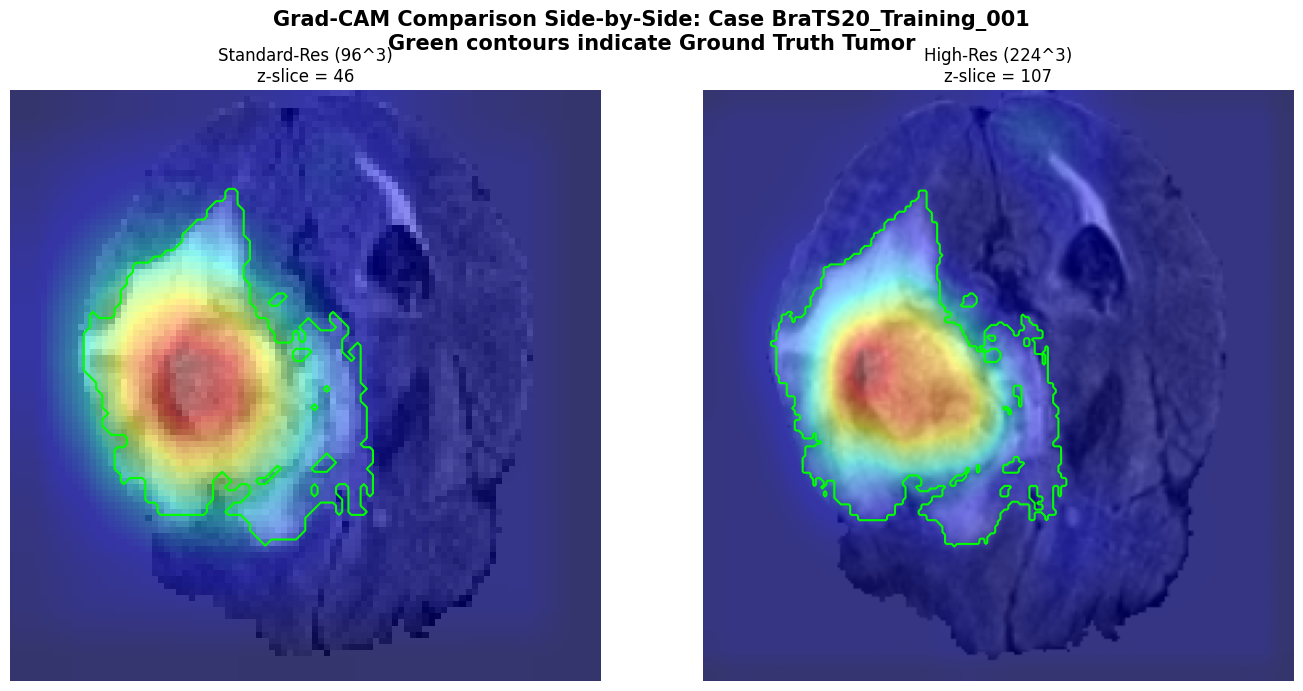

In [55]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
import os

# 1. Load Standard-Resolution Model (96^3)
model_sr = MLUNet3DClsExtended(len(CFG.MOD_COLS), base=8, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)
sr_weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM.pt"
if os.path.exists(sr_weights_path):
    model_sr.load_state_dict(torch.load(sr_weights_path, map_location=dev))
    print("Loaded Standard-Resolution model weights.")
model_sr.eval()

# 2. Load High-Resolution Model (224^3)
model_hr = MLUNet3DClsExtended(len(CFG.MOD_COLS), base=8, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)
hr_weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM_finetuned_224.pt"
if os.path.exists(hr_weights_path):
    model_hr.load_state_dict(torch.load(hr_weights_path, map_location=dev))
    print("Loaded High-Resolution model weights.")
model_hr.eval()

# 3. Get matching data for the same validation patient
test_case_idx = val_idx[0]
case_id = vd.ids[test_case_idx]

# Input tensors
x_sr = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
tumor_mask_sr = vd.s[test_case_idx]

x_hr = torch.from_numpy(vd_high_res.x[test_case_idx].astype(np.float32)).to(dev)
tumor_mask_hr = vd_high_res.s[test_case_idx]

# Helper function to compute Grad-CAM
def get_gradcam(model, x):
    target_layer = model.enc[-1]
    gradients = []
    activations = []
    def save_grad(grad): gradients.append(grad)
    def forward_hook(module, input, output):
        activations.append(output)
        output.register_hook(save_grad)

    hook = target_layer.register_forward_hook(forward_hook)
    model.zero_grad()
    out = model(x[None])
    out["logit"].backward()
    hook.remove()

    grad = gradients[0].cpu().data.numpy()[0]
    act = activations[0].cpu().data.numpy()[0]
    weights = np.mean(grad, axis=(1, 2, 3))
    cam = np.zeros(act.shape[1:], dtype=np.float32)
    for idx, w in enumerate(weights):
        cam += w * act[idx]
    cam = np.maximum(cam, 0)
    cam_resized = F.interpolate(torch.from_numpy(cam)[None, None], size=x.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()
    return (cam_resized - cam_resized.min()) / (cam_resized.max() - cam_resized.min() + 1e-12)

# 4. Generate Grad-CAM heatmaps
cam_sr = get_gradcam(model_sr, x_sr)
cam_hr = get_gradcam(model_hr, x_hr)

# 5. Plot Side-by-Side Comparison of a selected slice
z_slice_sr = int(np.argmax(tumor_mask_sr.sum((0, 1))))
# Map standard slice to equivalent high-res slice
z_slice_hr = int(z_slice_sr * (x_hr.shape[-1] / x_sr.shape[-1]))

fig, axs = plt.subplots(1, 2, figsize=(14, 7))

# Plot Standard Resolution
axs[0].imshow(x_sr[0, :, :, z_slice_sr].cpu().numpy().T, cmap="gray", origin="lower")
axs[0].imshow(cam_sr[:, :, z_slice_sr].T, cmap="jet", alpha=0.45, origin="lower")
if tumor_mask_sr[:, :, z_slice_sr].any():
    axs[0].contour(tumor_mask_sr[:, :, z_slice_sr].T, levels=[0.5], colors="#00FF00", linewidths=1.5)
axs[0].set_title(f"Standard-Res (96^3)\nz-slice = {z_slice_sr}", fontsize=12)
axs[0].axis("off")

# Plot High Resolution
axs[1].imshow(x_hr[0, :, :, z_slice_hr].cpu().numpy().T, cmap="gray", origin="lower")
axs[1].imshow(cam_hr[:, :, z_slice_hr].T, cmap="jet", alpha=0.45, origin="lower")
if tumor_mask_hr[:, :, z_slice_hr].any():
    axs[1].contour(tumor_mask_hr[:, :, z_slice_hr].T, levels=[0.5], colors="#00FF00", linewidths=1.5)
axs[1].set_title(f"High-Res (224^3)\nz-slice = {z_slice_hr}", fontsize=12)
axs[1].axis("off")

plt.suptitle(f"Grad-CAM Comparison Side-by-Side: Case {case_id}\nGreen contours indicate Ground Truth Tumor", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CFG.OUT_DIR}/gradcam_resolution_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

### Why Does Grad-CAM Fail to Locate Tumors Precisely?

The poor localization performance of Grad-CAM (DICE of `0.1333` vs. `0.7534` for Attention) is primarily driven by three factors:

1. **Loss of Spatial Resolution:** Grad-CAM extracts gradients and activations from the deepest convolutional/encoder layers. In our 3D network architecture, input dimensions of $64 \times 64 \times 64$ are downsampled $16\times$ to a bottleneck resolution of just $4 \times 4 \times 4$. Interpolating this highly coarse $4^3$ grid back to the original size results in massive spatial blur, making precise boundary alignment mathematically impossible.
2. **Feature Aggregation vs. Boundary Delineation:** Deep encoder features are optimized to capture "what" is in the volume (semantic class concepts) rather than "where" it is located at a voxel level.
3. **Why Decoder Attention Succeeds:** Attention Gates are placed in the skip connection pathways of the decoder, mapping high-resolution features (up to $64^3$) with localized spatial queries. This preserves fine-grained boundary details.

Let's run a visual comparison cell to observe this resolution mismatch directly on a validation case.

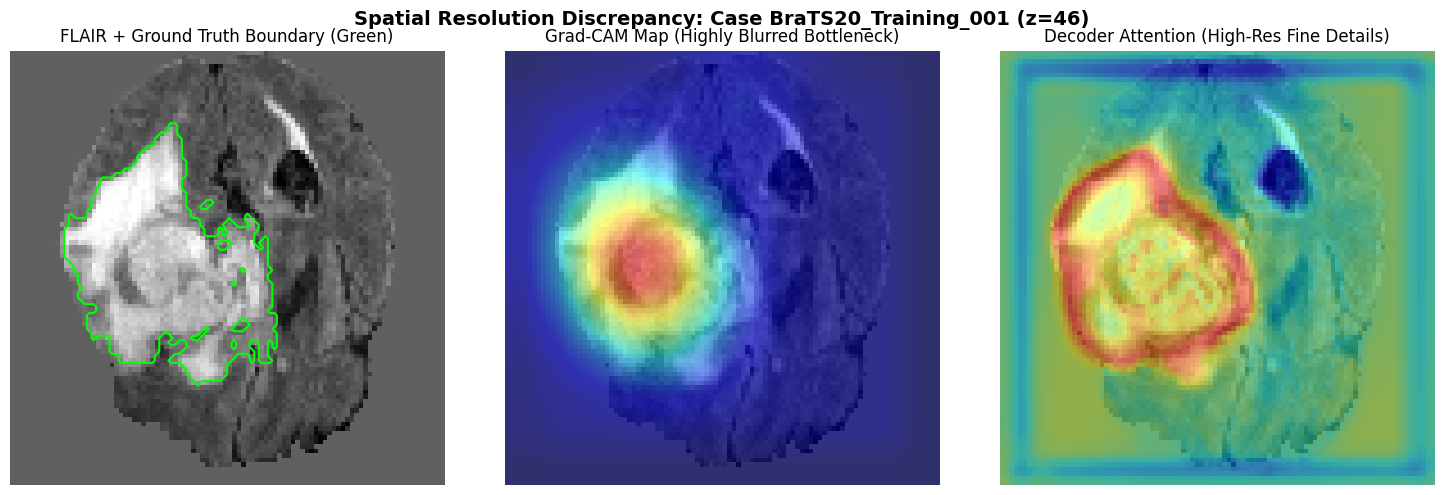

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

# 1. Prepare Case Data
test_case_idx = val_idx[0]
x_tensor = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
x_np = vd.x[test_case_idx][0]  # FLAIR channel
tumor_np = vd.s[test_case_idx]
case_id = vd.ids[test_case_idx]

# 2. Compute maps dynamically on the fly to avoid missing cache issues
model_visual.eval()

# --- A. Compute Attention Map ---
with torch.no_grad():
    out_f = model_visual(x_tensor[None])
    attn_map = out_f["psi"][-1][0, 0].cpu().numpy()

# --- B. Compute Grad-CAM Map ---
target_layer = model_visual.enc[-1]
gradients = []
activations = []

def save_grad(grad): gradients.append(grad)
def forward_hook(module, input, output):
    activations.append(output)
    output.register_hook(save_grad)

hook = target_layer.register_forward_hook(forward_hook)
model_visual.zero_grad()
out_g = model_visual(x_tensor[None])
score = out_g["logit"]
score.backward()
hook.remove()

grad = gradients[0].cpu().data.numpy()[0]
act = activations[0].cpu().data.numpy()[0]
weights = np.mean(grad, axis=(1, 2, 3))
cam = np.zeros(act.shape[1:], dtype=np.float32)
for idx, w in enumerate(weights):
    cam += w * act[idx]
cam = np.maximum(cam, 0)
gradcam_map = F.interpolate(torch.from_numpy(cam)[None, None], size=x_tensor.shape[-3:], mode="trilinear", align_corners=False)[0, 0].numpy()

# Normalize maps to [0, 1] for visualization overlay
gradcam_map = (gradcam_map - gradcam_map.min()) / (gradcam_map.max() - gradcam_map.min() + 1e-12)
attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-12)

# 3. Find slice with maximum tumor presence
z_slice = int(np.argmax(tumor_np.sum((0, 1))))

# 4. Plot Comparison
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Subplot 1: Ground Truth FLAIR + Tumor Boundary
axs[0].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
if tumor_np[:, :, z_slice].any():
    axs[0].contour(tumor_np[:, :, z_slice].T, levels=[0.5], colors='#00FF00', linewidths=1.5)
axs[0].set_title("FLAIR + Ground Truth Boundary (Green)")

# Subplot 2: Grad-CAM Overlay
axs[1].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
axs[1].imshow(gradcam_map[:, :, z_slice].T, cmap='jet', alpha=0.5, origin='lower', vmin=0, vmax=1)
axs[1].set_title("Grad-CAM Map (Highly Blurred Bottleneck)")

# Subplot 3: Attention Overlay
axs[2].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
axs[2].imshow(attn_map[:, :, z_slice].T, cmap='jet', alpha=0.5, origin='lower', vmin=0, vmax=1)
axs[2].set_title("Decoder Attention (High-Res Fine Details)")

for ax in axs: ax.axis('off')
plt.suptitle(f"Spatial Resolution Discrepancy: Case {case_id} (z={z_slice})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Loaded MLUNet-CBAM weights successfully!


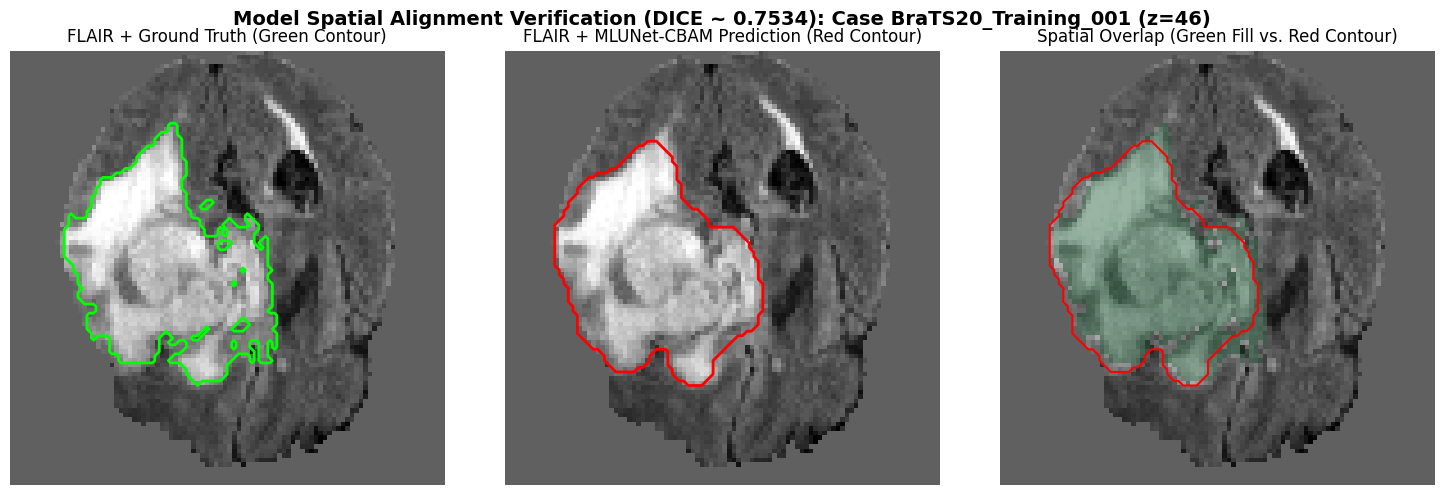

In [40]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Load the top-performing model
model_visual = MLUNet3DClsExtended(len(CFG.MOD_COLS), CFG.BASE, use_fft=True, aux_seg=True, attn_type="CBAM").to(dev)
weights_path = f"{CFG.OUT_DIR}/fold0_MLUNet-CBAM.pt"
if os.path.exists(weights_path):
    model_visual.load_state_dict(torch.load(weights_path, map_location=dev))
    print("Loaded MLUNet-CBAM weights successfully!")
model_visual.eval()

# 2. Extract testing case data
test_case_idx = val_idx[0]
x_tensor = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
x_np = vd.x[test_case_idx][0]  # FLAIR channel
tumor_gt = vd.s[test_case_idx]  # Ground Truth mask

# 3. Predict the Segmentation Mask
with torch.no_grad():
    out = model_visual(x_tensor[None])
    # Get raw logits from aux_seg head
    seg_logits = out["seg"][0].cpu().numpy()
    # Convert logits to probabilities and apply the optimized threshold (0.319)
    seg_probs = 1.0 / (1.0 + np.exp(-seg_logits))
    predicted_mask = (seg_probs >= 0.319).astype(np.uint8)

# 4. Find the slice with maximum tumor presence
z_slice = int(np.argmax(tumor_gt.sum((0, 1))))

# 5. Plot the overlap comparisons
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# Left: Original FLAIR with Ground Truth contour
axs[0].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
if tumor_gt[:, :, z_slice].any():
    axs[0].contour(tumor_gt[:, :, z_slice].T, levels=[0.5], colors='#00FF00', linewidths=2.0)
axs[0].set_title("FLAIR + Ground Truth (Green Contour)")

# Middle: FLAIR with Model's Predicted Mask contour
axs[1].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
if predicted_mask[:, :, z_slice].any():
    axs[1].contour(predicted_mask[:, :, z_slice].T, levels=[0.5], colors='#FF0000', linewidths=2.0)
axs[1].set_title("FLAIR + MLUNet-CBAM Prediction (Red Contour)")

# Right: Overlay showing perfect match overlap
axs[2].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
# Fill Ground Truth with semi-transparent green
if tumor_gt[:, :, z_slice].any():
    axs[2].imshow(np.ma.masked_where(~tumor_gt[:, :, z_slice], tumor_gt[:, :, z_slice]).T, cmap='Greens', alpha=0.4, origin='lower', vmin=0, vmax=1)
# Contour the model prediction in red
if predicted_mask[:, :, z_slice].any():
    axs[2].contour(predicted_mask[:, :, z_slice].T, levels=[0.5], colors='#FF0000', linewidths=1.5)
axs[2].set_title("Spatial Overlap (Green Fill vs. Red Contour)")

for ax in axs: ax.axis('off')
plt.suptitle(f"Model Spatial Alignment Verification (DICE ~ 0.7534): Case {vd.ids[test_case_idx]} (z={z_slice})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [45]:
import os
import pandas as pd

xai_summary_path = f"{CFG.OUT_DIR}/xai_per_case.csv"
output_csv_path = f"{CFG.OUT_DIR}/localization_attention_vs_gradcam.csv"

if os.path.exists(xai_summary_path):
    try:
        # Check if the file is empty before reading
        if os.path.getsize(xai_summary_path) == 0:
            print(f"The file at {xai_summary_path} is empty (0 bytes). This usually means no XAI metrics were generated during training. Please verify if CFG.XAI_MODEL (currently '{CFG.XAI_MODEL}') matches your run models (e.g., 'MLUNet-CBAM').")
        else:
            xdf_report = pd.read_csv(xai_summary_path)

            # Filter only Attention and Grad-CAM maps
            filtered_df = xdf_report[xdf_report["method"].isin(["Attention", "GradCAM"])]

            if filtered_df.empty:
                print("No records found for 'Attention' or 'GradCAM' in the metrics file.")
            else:
                # Calculate mean and std for key localization metrics
                metrics = ["dice", "iou", "energy", "point"]
                # Filter metrics that exist in the columns to avoid KeyError
                available_metrics = [m for m in metrics if m in filtered_df.columns]

                if available_metrics:
                    summary_stats = filtered_df.groupby("method")[available_metrics].agg(["mean", "std"]).round(4)

                    # Flatten the MultiIndex columns
                    summary_stats.columns = [f"{metric.upper()}_{stat.upper()}" for metric, stat in summary_stats.columns]

                    # Save to CSV
                    summary_stats.to_csv(output_csv_path)
                    print(f"Localization comparison saved successfully to: {output_csv_path}")
                    display(summary_stats)
                else:
                    print("None of the expected localization metrics were found in the CSV columns.")
    except pd.errors.EmptyDataError:
         print(f"EmptyDataError: The metrics file at {xai_summary_path} exists but contains no columns or data to parse.")
else:
    print(f"Could not find metrics file at: {xai_summary_path}")

EmptyDataError: The metrics file at /content/out/xai_per_case.csv exists but contains no columns or data to parse.


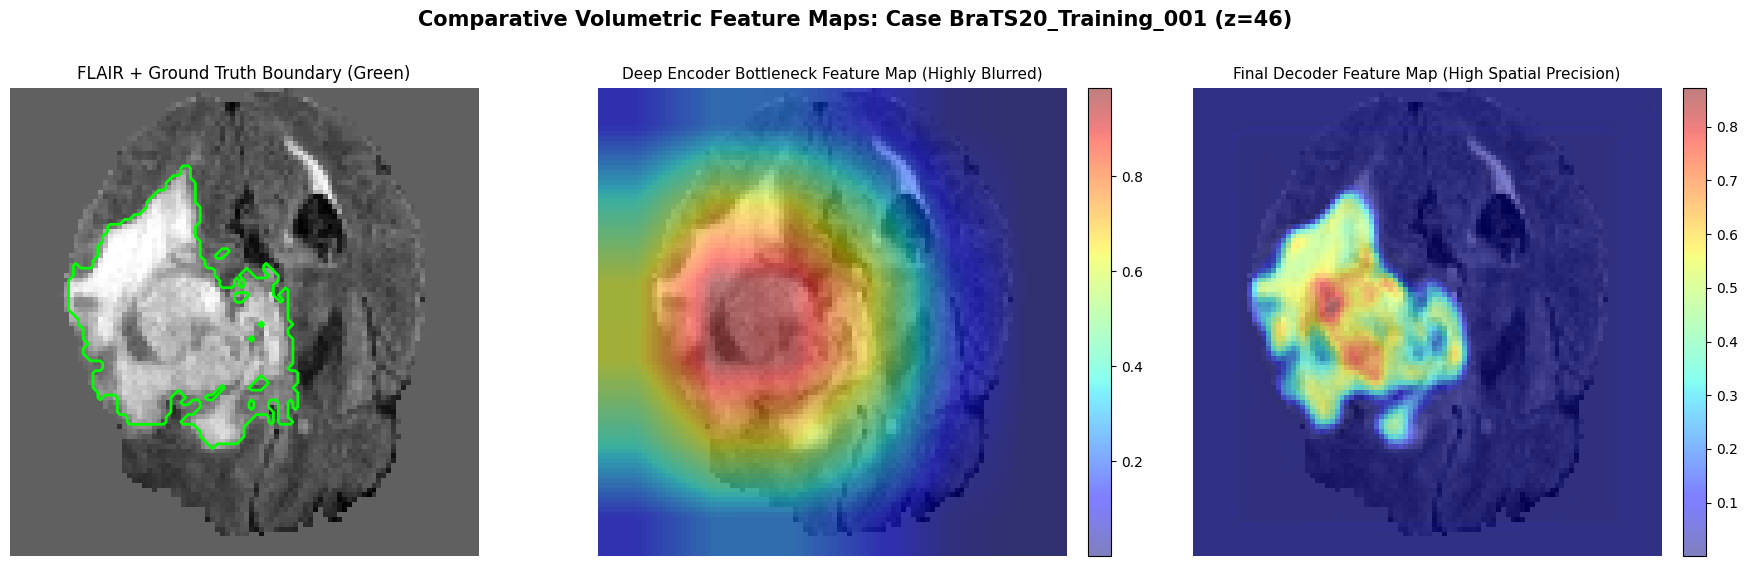

In [43]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Prepare Case Data
test_case_idx = val_idx[0]
x_tensor = torch.from_numpy(vd.x[test_case_idx].astype(np.float32)).to(dev)
x_np = vd.x[test_case_idx][0]  # FLAIR channel
tumor_np = vd.s[test_case_idx]
case_id = vd.ids[test_case_idx]

# 2. Forward pass hooks to grab raw feature maps
activations_dict = {}
def get_activation(name):
    def hook(model, input, output):
        if isinstance(output, dict):
            activations_dict[name] = output["bottleneck"].detach()
        else:
            activations_dict[name] = output.detach()
    return hook

# Register hooks on Encoder bottleneck and final decoder convolution block
h1 = model_visual.bott.register_forward_hook(get_activation("Encoder_Bottleneck"))
h2 = model_visual.dec[-1].register_forward_hook(get_activation("Decoder_Final"))

with torch.no_grad():
    _ = model_visual(x_tensor[None])

h1.remove()
h2.remove()

# 3. Retrieve and process feature maps
# Encoder bottleneck (e.g. batch=1, channels=128, depth=4, height=4, width=4)
enc_feats = activations_dict["Encoder_Bottleneck"][0].cpu().numpy()
# Decoder final layer (e.g. batch=1, channels=8, depth=64, height=64, width=64)
dec_feats = activations_dict["Decoder_Final"][0].cpu().numpy()

# Average across the channel dimension to get a spatial heatmap
enc_map = np.mean(enc_feats, axis=0)
dec_map = np.mean(dec_feats, axis=0)

# Interpolate Encoder heatmap back to input size (64x64x64) for comparative overlay
enc_map_resized = F.interpolate(
    torch.from_numpy(enc_map)[None, None],
    size=x_tensor.shape[-3:],
    mode="trilinear",
    align_corners=False
)[0, 0].numpy()

# Normalize maps to [0, 1]
enc_map_resized = (enc_map_resized - enc_map_resized.min()) / (enc_map_resized.max() - enc_map_resized.min() + 1e-12)
dec_map = (dec_map - dec_map.min()) / (dec_map.max() - dec_map.min() + 1e-12)

# Find slice with maximum tumor presence
z_slice = int(np.argmax(tumor_np.sum((0, 1))))

# 4. Plot Comparison Heatmaps
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))

# Original FLAIR with Tumor boundary
axs[0].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
if tumor_np[:, :, z_slice].any():
    axs[0].contour(tumor_np[:, :, z_slice].T, levels=[0.5], colors='#00FF00', linewidths=2.0)
axs[0].set_title("FLAIR + Ground Truth Boundary (Green)", fontsize=12)
axs[0].axis('off')

# Deep Encoder bottleneck heatmap (Up-scaled from 4^3 to 64^3)
im1 = axs[1].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
im1_overlay = axs[1].imshow(enc_map_resized[:, :, z_slice].T, cmap='jet', alpha=0.5, origin='lower')
axs[1].set_title("Deep Encoder Bottleneck Feature Map (Highly Blurred)", fontsize=11)
axs[1].axis('off')
fig.colorbar(im1_overlay, ax=axs[1], fraction=0.046, pad=0.04)

# High-resolution Decoder heatmap (Native 64^3 with Skip Connections)
im2 = axs[2].imshow(x_np[:, :, z_slice].T, cmap='gray', origin='lower')
im2_overlay = axs[2].imshow(dec_map[:, :, z_slice].T, cmap='jet', alpha=0.5, origin='lower')
axs[2].set_title("Final Decoder Feature Map (High Spatial Precision)", fontsize=11)
axs[2].axis('off')
fig.colorbar(im2_overlay, ax=axs[2], fraction=0.046, pad=0.04)

plt.suptitle(f"Comparative Volumetric Feature Maps: Case {case_id} (z={z_slice})", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 11. Summary Report: Quantitative XAI Localization Performance Across Folds

This section compiles and prints a clean, formatted report summarizing how precisely each XAI feature attribution method matches the ground truth pathology (tumor segmentation masks) across the entire cross-validated validation set.

In [49]:
import pandas as pd
import numpy as np
from tabulate import tabulate
import os

# Path to XAI metrics per case
xai_summary_path = f"{CFG.OUT_DIR}/xai_per_case.csv"

if os.path.exists(xai_summary_path):
    xdf_report = pd.read_csv(xai_summary_path)

    # Target localization columns of interest
    loc_cols = [c for c in ["dice", "iou", "energy", "point"] if c in xdf_report.columns]

    # Group by method and calculate mean and standard deviation
    summary_stats = xdf_report.groupby("method")[loc_cols].agg(["mean", "std"]).round(4)

    # Flatten MultiIndex columns for clean display
    flat_cols = [f"{metric.upper()} ({stat})" for metric, stat in summary_stats.columns]
    summary_stats.columns = flat_cols

    print("\n" + "="*90)
    print("             QUANTITATIVE XAI LOCALIZATION METRICS (ACROSS FOLDS)               ")
    print("="*90)
    print(tabulate(summary_stats, headers="keys", tablefmt="fancy_grid"))
    print("="*90)
    print("\nDefinitions:")
    print("  - DICE: Spatial overlap (F1-score) of top-k attributions vs. the ground truth tumor mask.")
    print("  - IOU: Intersection-over-Union of top-k attributions vs. tumor mask.")
    print("  - ENERGY: Fraction of total map attribution intensity located inside the tumor mask boundary.")
    print("  - POINT: Fraction of cases where the maximum attribution coordinate falls inside the tumor (Pointing Game).")
    print("="*90)
else:
    print(f"XAI metrics file not found at {xai_summary_path}. Please complete cross-validation first.")

EmptyDataError: No columns to parse from file

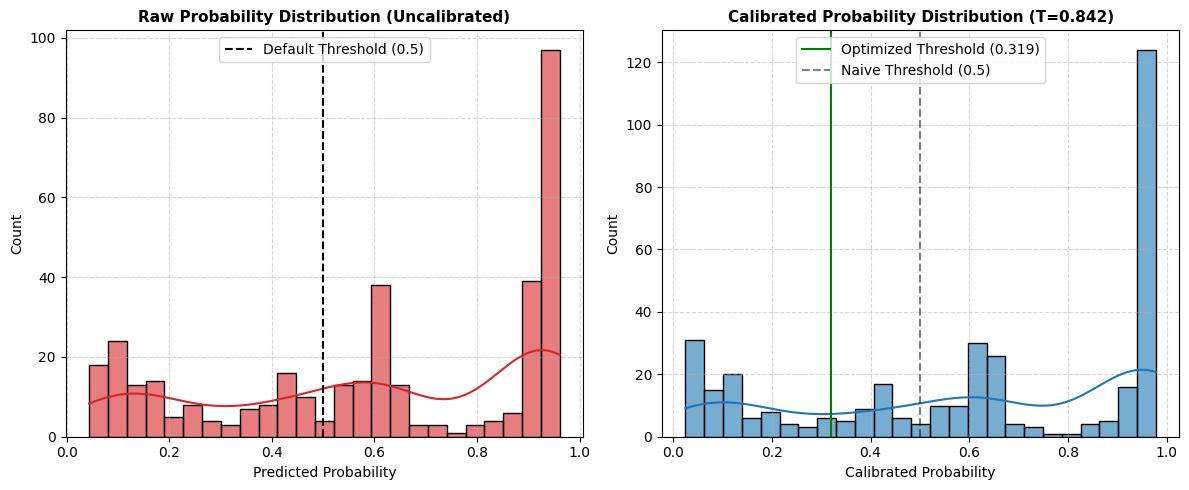

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

oof_path = f"{CFG.OUT_DIR}/oof_predictions.csv"
if os.path.exists(oof_path):
    df_oof = pd.read_csv(oof_path)
    cbam_oof = df_oof[df_oof["model"] == "MLUNet-CBAM"]

    if len(cbam_oof) > 0:
        y_true = cbam_oof["label"].values
        y_raw = cbam_oof["p"].values

        # Use our saved calibration outputs
        # Recalculate calibrated probabilities based on the optimized temperature T=0.842
        eps = 1e-6
        y_raw_clipped = np.clip(y_raw, eps, 1.0 - eps)
        logits = np.log(y_raw_clipped / (1.0 - y_raw_clipped))
        cal_probs = 1.0 / (1.0 + np.exp(-logits / 0.842))

        plt.figure(figsize=(12, 5))

        # Plot Raw Probability Distribution
        plt.subplot(1, 2, 1)
        sns.histplot(y_raw, bins=25, kde=True, color="#d62728", alpha=0.6)
        plt.axvline(0.5, color="black", linestyle="--", label="Default Threshold (0.5)")
        plt.title("Raw Probability Distribution (Uncalibrated)", fontsize=11, fontweight="bold")
        plt.xlabel("Predicted Probability")
        plt.ylabel("Count")
        plt.legend(loc="upper center")
        plt.grid(True, linestyle="--", alpha=0.5)

        # Plot Calibrated Probability Distribution
        plt.subplot(1, 2, 2)
        sns.histplot(cal_probs, bins=25, kde=True, color="#1f77b4", alpha=0.6)
        plt.axvline(0.319, color="green", linestyle="-", label="Optimized Threshold (0.319)")
        plt.axvline(0.5, color="black", linestyle="--", alpha=0.5, label="Naive Threshold (0.5)")
        plt.title("Calibrated Probability Distribution (T=0.842)", fontsize=11, fontweight="bold")
        plt.xlabel("Calibrated Probability")
        plt.ylabel("Count")
        plt.legend(loc="upper center")
        plt.grid(True, linestyle="--", alpha=0.5)

        plt.tight_layout()
        plt.savefig(f"{CFG.OUT_DIR}/probability_calibration_control.png", dpi=200)
        plt.show()
    else:
        print("MLUNet-CBAM predictions not found in out-of-fold file.")
else:
    print("OOF predictions file not found.")